# Modelo de predicción para la Champions League (y cualquier liga)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tontoni0/apuestas-deportes/blob/modelo-champions/notebooks/modelo_champions.ipynb)

**Qué hace este cuaderno**

1. Descarga resultados y cuotas de 15 ligas europeas y de la Champions/Europa League (2018 a hoy).
2. Calcula cinco modelos: Dixon-Coles, regresión logística con Elo, regresión lineal, regresión de Poisson y XGBoost.
3. Los combina en un ensamble y lo mezcla con las cuotas del mercado.
4. Simula cada partido 100,000 veces (Monte Carlo) para sacar marcadores, over/under y ambos anotan.
5. Hace el backtest que sugirió tu amigo: entrena con 3 temporadas, predice las 2 siguientes sin verlas y mide la tasa de acierto.

**Cómo usarlo desde el teléfono**

* Abre el enlace de Colab de arriba. Menú `Entorno de ejecución` > `Ejecutar todo`. Tarda de 2 a 4 minutos.
* Antes de cada jornada edita solo la celda **Configuración**: resultados nuevos, partidos, cuotas y bajas.
* En Colab el cuaderno baja datos frescos de football-data.co.uk. Si esa web falla, usa un espejo en GitHub con datos hasta septiembre de 2026.

**Advertencia.** En el backtest el modelo no le gana a las cuotas de Bet365. Úsalo para entender probabilidades, no como garantía de ganancia.


In [1]:
!pip -q install xgboost scikit-learn scipy pandas matplotlib 2>/dev/null | tail -1

## Configuración de la jornada (EDITA ESTA CELDA ANTES DE CADA JORNADA)

Esta es la única celda que necesitas editar. Los nombres de equipos siguen el formato de football-data.co.uk (por ejemplo `Ath Madrid`, `Sp Lisbon`, `Paris SG`, `Man United`).

In [2]:
# 1) Resultados de la Champions 2026-27 ya jugados. Agrega filas después de cada jornada.
#    Columnas: date, home, hc (país local), away, ac (país visita), hg, ag, home_factor (1 = localía normal)
UCL_2026_27 = """date,home,hc,away,ac,hg,ag,home_factor
2026-09-08,AEK,GRE,LASK,AUT,1,0,1
2026-09-08,Club Brugge,BEL,Aston Villa,ENG,2,3,1
2026-09-08,Dortmund,GER,Villarreal,ESP,3,2,1
2026-09-08,Porto,POR,Man City,ENG,0,2,1
2026-09-08,Lille,FRA,Betis,ESP,2,3,1
2026-09-08,Real Madrid,ESP,Inter,ITA,2,1,1
2026-09-09,Barcelona,ESP,Feyenoord,NED,5,1,1
2026-09-09,Stuttgart,GER,Viking,NOR,3,1,1
2026-09-09,Liverpool,ENG,Ath Madrid,ESP,2,1,1
2026-09-09,Paris SG,FRA,Slovan Bratislava,SVK,6,1,1
2026-09-09,Sp Lisbon,POR,Galatasaray,TUR,3,1,1
2026-09-09,Napoli,ITA,Arsenal,ENG,0,1,1
2026-09-10,Fenerbahce,TUR,Roma,ITA,1,1,1
2026-09-10,PSV Eindhoven,NED,Shakhtar Donetsk,UKR,1,1,1
2026-09-10,Como,ITA,RB Leipzig,GER,4,1,1
2026-09-10,Bayern Munich,GER,Bodo/Glimt,NOR,5,0,1
2026-09-10,Man United,ENG,Sabah,AZE,4,0,1
2026-09-10,Slavia Praha,CZE,Lens,FRA,2,3,1
2026-10-13,Lens,FRA,Sp Lisbon,POR,0,2,1
2026-10-13,Sabah,AZE,Slavia Praha,CZE,2,0,1
2026-10-13,Arsenal,ENG,Lille,FRA,3,0,1
2026-10-13,Ath Madrid,ESP,Man United,ENG,2,0,1
2026-10-13,Galatasaray,TUR,Barcelona,ESP,1,4,1
2026-10-13,Inter,ITA,Club Brugge,BEL,3,4,1
2026-10-13,RB Leipzig,GER,PSV Eindhoven,NED,1,0,1
2026-10-13,Viking,NOR,Bayern Munich,GER,3,3,1
2026-10-13,Villarreal,ESP,Napoli,ITA,3,1,1
2026-10-14,Feyenoord,NED,Como,ITA,3,2,1
2026-10-14,LASK,AUT,Liverpool,ENG,3,6,1
2026-10-14,Roma,ITA,Real Madrid,ESP,3,4,1
2026-10-14,Aston Villa,ENG,Fenerbahce,TUR,6,0,1
2026-10-14,Shakhtar Donetsk,UKR,AEK,GRE,3,1,0.4
2026-10-14,Bodo/Glimt,NOR,Dortmund,GER,1,0,1
2026-10-14,Man City,ENG,Paris SG,FRA,2,4,1
2026-10-14,Betis,ESP,Porto,POR,3,2,1
2026-10-14,Slovan Bratislava,SVK,Stuttgart,GER,0,3,1
2026-10-20,Fenerbahce,TUR,Slavia Praha,CZE,2,2,1
2026-10-20,Sabah,AZE,Dortmund,GER,1,2,1
2026-10-20,Roma,ITA,Slovan Bratislava,SVK,4,0,1
2026-10-20,Porto,POR,PSV Eindhoven,NED,0,1,1
2026-10-20,Liverpool,ENG,Villarreal,ESP,4,3,1
2026-10-20,Man City,ENG,AEK,GRE,5,1,1
2026-10-20,Napoli,ITA,Bodo/Glimt,NOR,4,3,1
2026-10-20,Paris SG,FRA,Barcelona,ESP,4,2,1
2026-10-20,Stuttgart,GER,Ath Madrid,ESP,1,1,1
2026-10-21,Como,ITA,Man United,ENG,4,1,1
2026-10-21,Lille,FRA,Galatasaray,TUR,2,4,1
2026-10-21,Aston Villa,ENG,Viking,NOR,3,1,1
2026-10-21,Club Brugge,BEL,Lens,FRA,3,0,1
2026-10-21,Bayern Munich,GER,Arsenal,ENG,2,2,1
2026-10-21,Inter,ITA,Shakhtar Donetsk,UKR,1,0,1
2026-10-21,Real Madrid,ESP,RB Leipzig,GER,4,1,1
2026-10-21,Betis,ESP,Feyenoord,NED,1,0,1
2026-10-21,Sp Lisbon,POR,LASK,AUT,2,3,1
"""

# 2) Partidos a predecir. Cuotas decimales (momios europeos). NaN = no encontrada.
#    factor_localia: 1 = estadio propio; 0.4 = Shakhtar juega lejos de Ucrania; 0 = cancha neutral.
#    fuente_cuotas: de dónde salió cada línea (revisa y actualiza antes del partido).
NaN = float("nan")
PARTIDOS = [
    # fecha, hora CET, local, visita, factor_localia, cuota 1, X, 2, fuente
    ("2026-11-03", "18:45", "Shakhtar Donetsk", "Sp Lisbon", 0.4, 3.60, 3.80, 2.05, "Oddschecker (hace ~20 días)"),
    ("2026-11-03", "18:45", "Galatasaray", "Stuttgart", 1.0, 2.20, 4.00, 3.00, "Oddschecker (hace ~20 días)"),
    ("2026-11-03", "21:00", "Ath Madrid", "Bayern Munich", 1.0, 3.33, 4.35, 2.00, "Polymarket 30/23/50 c"),
    ("2026-11-03", "21:00", "Barcelona", "Aston Villa", 1.0, 1.27, NaN, 10.50, "1xBet / LetsBetMD"),
    ("2026-11-03", "21:00", "Feyenoord", "Inter", 1.0, 4.51, 4.33, 1.75, "1xBet (rg.org) + Oddschecker"),
    ("2026-11-03", "21:00", "Bodo/Glimt", "Lille", 1.0, 1.92, 4.10, 4.00, "1xBet + Oddschecker"),
    ("2026-11-03", "21:00", "LASK", "Slovan Bratislava", 1.0, 1.43, 5.00, 6.67, "Oddschecker / rg.org"),
    ("2026-11-03", "21:00", "Man United", "Roma", 1.0, 2.375, 3.95, NaN, "bet365 (Squawka) + 1xBet"),
    ("2026-11-03", "21:00", "Villarreal", "Paris SG", 1.0, NaN, 4.88, 1.60, "RotoWire / 1xBet"),
    ("2026-11-04", "18:45", "Fenerbahce", "Liverpool", 1.0, 5.00, 4.60, 1.62, "Oddschecker / Covers"),
    ("2026-11-04", "18:45", "AEK", "Real Madrid", 1.0, 8.75, NaN, 1.30, "casas EE. UU. (-333/+775)"),
    ("2026-11-04", "21:00", "Dortmund", "Betis", 1.0, 1.75, NaN, 4.33, "Oddschecker"),
    ("2026-11-04", "21:00", "Porto", "Napoli", 1.0, 2.05, NaN, 3.70, "Oddschecker"),
    ("2026-11-04", "21:00", "PSV Eindhoven", "Club Brugge", 1.0, 2.10, NaN, 4.33, "Oddschecker"),
    ("2026-11-04", "21:00", "RB Leipzig", "Man City", 1.0, 5.25, NaN, 1.55, "BetRivers (-182/+425)"),
    ("2026-11-04", "21:00", "Lens", "Como", 1.0, 3.10, NaN, 2.20, "Oddschecker / bet365"),
    ("2026-11-04", "21:00", "Slavia Praha", "Arsenal", 1.0, NaN, NaN, 1.31, "DraftKings (-320)"),
    ("2026-11-04", "21:00", "Viking", "Sabah", 1.0, 1.52, 4.90, NaN, "Kalshi 66% + 1xBet"),
]

# 3) Ajuste por bajas, en puntos Elo (negativo = el equipo pierde fuerza).
#    Guía usada: delantero o mediocampista titular de élite -15 a -20; defensa titular -8 a -12;
#    portero titular -10 a -15; suplente -3 a -5. Se suman y se recortan a -60.
#    Fuente: previas del 2-3 nov 2026 (UEFA, Khelnow, RotoWire, This is Anfield). CONFIRMA CON LAS ALINEACIONES.
AJUSTES_BAJAS = {
    "Paris SG": -55,      # Dembélé, Kvaratskhelia, Marquinhos, Nuno Mendes fuera (confianza media)
    "Barcelona": -25,     # Koundé, Christensen, Eric García fuera; Olmo duda
    "Aston Villa": -12,   # Ruggeri, Wan-Bissaka fuera; Onana duda
    "Bayern Munich": -25, # Luis Díaz fuera; Olise y Neuer en duda
    "Ath Madrid": -5,     # Johnny Cardoso fuera
    "Inter": -25,         # Lautaro fuera, Bastoni sancionado (confianza baja, una sola fuente)
    "Liverpool": -25,     # Ekitiké, Frimpong, Bradley, Leoni fuera; Szoboszlai duda
    "Man City": -8,       # Stones fuera, Aké duda
    "RB Leipzig": -5,     # Marc Guiu fuera
    "Lens": -20,          # Edouard, Sima, Ganiou fuera
    "Napoli": -12,        # De Bruyne lesionado
    "Sp Lisbon": -12,     # Debast, Nuno Santos fuera; Zalazar duda
    "Shakhtar Donetsk": -4,  # Marlon fuera
    "Fenerbahce": -12,    # Asensio fuera; Oppong duda
    "Dortmund": -5,       # Emre Can fuera
}

# 4) Parámetros generales
MODO_DATOS = "auto"          # "auto" intenta football-data.co.uk (fresco) y si falla usa el espejo de GitHub
TEMPORADAS_ENTRENAR = (2021, 2022, 2023)   # 2021-22, 2022-23, 2023-24
TEMPORADAS_PROBAR = (2024, 2025)           # 2024-25, 2025-26
N_SIMULACIONES = 100_000

## Código del modelo

Las siguientes celdas definen las funciones. No hace falta tocarlas. Resumen de cada pieza:

* **Elo propio.** Cada equipo arranca con su Elo de ClubElo y sube o baja después de cada partido (liga o Europa). Ganar por más goles mueve más puntos. Los partidos europeos pesan más (K=30 contra K=20) porque son los únicos que conectan ligas distintas.
* **Dixon-Coles.** Estima ataque y defensa de cada equipo con un modelo de Poisson. Los partidos viejos pesan menos (vida media de un año). Corrige la frecuencia de 0-0, 1-0, 0-1 y 1-1. Los equipos con pocos datos (Sabah, Slavia, Slovan) se apoyan en su Elo.
* **Regresión logística.** Probabilidad de 1, X o 2 a partir de la diferencia de Elo y la localía.
* **Regresión lineal.** Predice la diferencia de goles y la convierte en 1X2 con una distribución normal.
* **Regresión de Poisson.** Predice goles de cada equipo con Elo y forma reciente.
* **XGBoost.** Árboles de decisión que combinan todas las variables anteriores.
* **Ensamble.** Promedio ponderado; los pesos salen de minimizar el error en temporadas que el modelo no vio.
* **Monte Carlo.** Simula 100,000 marcadores por partido con ruido en las tasas de gol para reflejar la incertidumbre del modelo.

### Librerías y configuración general

In [3]:
import os, re, io, json, math, time, warnings, difflib, unicodedata, urllib.request
from datetime import timedelta
import numpy as np
import pandas as pd
from scipy.optimize import minimize, minimize_scalar, least_squares
from scipy.stats import poisson, norm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

CACHE_DIR = os.environ.get("FM_CACHE", "datos_cache")
os.makedirs(CACHE_DIR, exist_ok=True)

# Ligas domésticas usadas (código football-data -> país)
DIVS_MAIN = ["E0", "SP1", "I1", "D1", "F1", "P1", "N1", "B1", "T1", "G1", "SC0"]
DIVS_EXTRA = {"AUT": "AUT", "NOR": "NOR", "SUI": "SWZ", "DEN": "DNK"}  # código interno -> archivo /new/
DIV_COUNTRY = {"E0": "ENG", "SP1": "ESP", "I1": "ITA", "D1": "GER", "F1": "FRA", "P1": "POR",
               "N1": "NED", "B1": "BEL", "T1": "TUR", "G1": "GRE", "SC0": "SCO", "AUT": "AUT",
               "NOR": "NOR", "SUI": "SUI", "DEN": "DEN"}
OF_LEAGUES = {"en.1": "E0", "es.1": "SP1", "de.1": "D1", "it.1": "I1", "fr.1": "F1", "pt.1": "P1", "nl.1": "N1"}

# Elo inicial por país para clubes sin historial (solo se usa si no hay semilla ClubElo)
COUNTRY_DEFAULT_ELO = {"CZE": 1620, "UKR": 1600, "SVK": 1470, "AZE": 1520, "KAZ": 1450, "CYP": 1520,
                       "CRO": 1590, "SRB": 1580, "SUI": 1600, "HUN": 1550, "ISR": 1520, "BUL": 1520,
                       "MDA": 1450, "LVA": 1420, "FIN": 1420, "IRL": 1350, "SWE": 1520, "POL": 1520,
                       "ROU": 1500, "RUS": 1650, "KOS": 1400, "SVN": 1450, "NOR": 1550, "DEN": 1580,
                       "AUT": 1580, "BEL": 1620, "SCO": 1600, "GRE": 1600, "TUR": 1620, "NED": 1650,
                       "POR": 1680, "FRA": 1680, "GER": 1700, "ITA": 1700, "ESP": 1720, "ENG": 1740}

XG_BASE = "https://raw.githubusercontent.com/xgabora/Club-Football-Match-Data-2000-2025/main/data/"
OF_BASE = "https://raw.githubusercontent.com/openfootball/football.json/master/"
OFCL_BASE = "https://raw.githubusercontent.com/openfootball/champions-league/master/"
FD_BASE = "https://www.football-data.co.uk/"


def http_get(url, timeout=40, cache=True):
    """Descarga con caché en disco."""
    fn = os.path.join(CACHE_DIR, re.sub(r"[^A-Za-z0-9._-]", "_", url)[-150:])
    if cache and os.path.exists(fn) and os.path.getsize(fn) > 0:
        with open(fn, "rb") as f:
            return f.read()
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (modelo-futbol)"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        data = r.read()
    if cache:
        with open(fn, "wb") as f:
            f.write(data)
    return data

### Normalización de nombres de equipos

In [4]:
_TRANS = str.maketrans({"ø": "o", "Ø": "O", "ł": "l", "Ł": "L", "ı": "i", "İ": "I", "æ": "ae", "ß": "ss",
                        "đ": "d", "Đ": "D", "ð": "d", "þ": "th"})
STOP = {"fc", "cf", "afc", "sc", "sk", "sl", "ssc", "ac", "kv", "bc", "pae", "sfp", "fk", "cp", "sv",
        "tsg", "ogc", "osc", "bsc", "gnk", "pfc", "bk", "kaa", "krc", "rsc", "club", "de", "futbol",
        "calcio", "1907", "1909", "1899", "1846", "04", "29", "sad", "the", "cfc", "as", "rc", "hnk", "nk",
        "ff", "if", "65", "1963"}

ALIAS = {
    "Bayern München": "Bayern Munich", "FC Bayern München": "Bayern Munich",
    "Club Atlético de Madrid": "Ath Madrid", "Atlético Madrid": "Ath Madrid", "Athletic Club": "Ath Bilbao",
    "Sporting Clube de Portugal": "Sp Lisbon", "Sporting CP": "Sp Lisbon",
    "Sporting Braga": "Sp Braga", "Sporting Clube de Braga": "Sp Braga", "SC Braga": "Sp Braga",
    "Sport Lisboa e Benfica": "Benfica", "SL Benfica": "Benfica",
    "FC Internazionale Milano": "Inter", "AC Milan": "Milan",
    "Paris Saint-Germain": "Paris SG", "Paris Saint-Germain FC": "Paris SG",
    "Manchester City": "Man City", "Manchester City FC": "Man City",
    "Manchester United": "Man United", "Manchester United FC": "Man United",
    "PSV": "PSV Eindhoven", "Feyenoord Rotterdam": "Feyenoord", "Club Brugge KV": "Club Brugge",
    "Royale Union Saint-Gilloise": "St. Gilloise", "Union Saint-Gilloise": "St. Gilloise",
    "FK Bodø/Glimt": "Bodo/Glimt", "Bodoe Glimt": "Bodo/Glimt",
    "Olympiakos Piraeus": "Olympiakos", "PAE Olympiakos SFP": "Olympiakos", "Olympiacos": "Olympiakos",
    "AEK Athen": "AEK", "AEK Athens": "AEK", "PAOK Saloniki": "PAOK",
    "Eintracht Frankfurt": "Ein Frankfurt", "Bayer 04 Leverkusen": "Leverkusen", "Bayer Leverkusen": "Leverkusen",
    "Bor. Mönchengladbach": "M'gladbach", "Borussia Mönchengladbach": "M'gladbach",
    "1899 Hoffenheim": "Hoffenheim", "TSG 1899 Hoffenheim": "Hoffenheim", "1. FC Union Berlin": "Union Berlin",
    "Real Sociedad de Fútbol": "Sociedad", "Real Sociedad": "Sociedad", "Real Betis": "Betis",
    "Real Betis Balompié": "Betis", "Real Madrid CF": "Real Madrid", "Deportivo Alavés": "Alaves",
    "Lazio Roma": "Lazio", "SS Lazio": "Lazio", "AS Roma": "Roma", "Olympique Lyonnais": "Lyon",
    "Olympique Marseille": "Marseille", "Olympique de Marseille": "Marseille", "Stade Rennais": "Rennes",
    "Stade Rennais FC 1901": "Rennes", "Stade Brestois 29": "Brest", "Racing Club de Lens": "Lens",
    "Tottenham Hotspur": "Tottenham", "Tottenham Hotspur FC": "Tottenham", "Newcastle United FC": "Newcastle",
    "Newcastle United": "Newcastle", "West Ham United": "West Ham", "West Ham United FC": "West Ham",
    "Leicester City": "Leicester", "Brighton & Hove Albion": "Brighton", "Brighton & Hove Albion FC": "Brighton",
    "Wolverhampton Wanderers": "Wolves", "Wolverhampton Wanderers FC": "Wolves", "Nottingham Forest": "Nott'm Forest",
    "Nottingham Forest FC": "Nott'm Forest", "AFC Ajax": "Ajax", "FC Twente": "Twente",
    "FC Red Bull Salzburg": "Salzburg", "RB Salzburg": "Salzburg", "SK Sturm Graz": "Sturm Graz",
    "Rapid Wien": "SK Rapid", "SK Rapid Wien": "SK Rapid", "Wolfsberger AC": "Wolfsberger AC",
    "FC København": "FC Copenhagen", "Brøndby IF": "Brondby", "İstanbul Başakşehir": "Buyuksehyr",
    "Beşiktaş": "Besiktas", "Fenerbahçe": "Fenerbahce", "Galatasaray SK": "Galatasaray",
    "Qarabağ Ağdam FK": "Qarabag", "Qarabağ FK": "Qarabag", "Dinamo Kiev": "Dynamo Kyiv",
    "FK Shakhtar Donetsk": "Shakhtar Donetsk", "SK Slavia Praha": "Slavia Praha",
    "ŠK Slovan Bratislava": "Slovan Bratislava", "GNK Dinamo Zagreb": "Dinamo Zagreb",
    "FK Crvena Zvezda": "Crvena Zvezda", "Red Star Belgrade": "Crvena Zvezda", "AC Sparta Praha": "Sparta Praha",
    "Viktoria Plzeň": "Plzen", "Ferencvárosi TC": "Ferencvaros", "PFC Ludogorets Razgrad": "Ludogorets",
    "FC Sheriff": "Sheriff", "FK Kairat": "Kairat", "Paphos FC": "Paphos",
    "Girona FC": "Girona", "Villarreal CF": "Villarreal", "Sevilla FC": "Sevilla", "Valencia CF": "Valencia",
    "Granada CF": "Granada", "Celtic FC": "Celtic", "Rangers FC": "Rangers", "Molde FK": "Molde",
    "LASK Linz": "LASK", "Slavia Prague": "Slavia Praha", "Slovan": "Slovan Bratislava", "Shakhtar": "Shakhtar Donetsk",
    "Sabah FK": "Sabah", "Sabah FC": "Sabah", "NEC": "Nijmegen", "NEC Nijmegen": "Nijmegen",
}


def _strip_accents(s):
    s = str(s).translate(_TRANS)
    return "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c))


def norm_name(s):
    s = _strip_accents(s).lower().replace("&", " ")
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    s = s.replace("oe", "o").replace("ae", "a").replace("ue", "u")  # Malmoe = Malmö = Malmo
    toks = [t for t in s.split() if t not in STOP]
    return " ".join(toks) if toks else s.strip()


def pretty_name(s):
    s = _strip_accents(s)
    toks = s.replace("-", " - ").split()
    while toks and toks[0].lower().strip(".") in STOP:
        toks = toks[1:]
    while toks and toks[-1].lower().strip(".") in STOP:
        toks = toks[:-1]
    return " ".join(toks).replace(" - ", "-") if toks else s


class NameResolver:
    """Convierte nombres de distintas fuentes a un nombre canónico (estilo football-data)."""

    def __init__(self):
        self.pool = {}   # país -> set de nombres canónicos
        self.cache = {}

    def add_pool(self, country, names):
        self.pool.setdefault(country, set()).update([n for n in names if isinstance(n, str)])

    def resolve(self, name, country=None):
        key = (name, country)
        if key in self.cache:
            return self.cache[key]
        out = self._resolve(name, country)
        self.cache[key] = out
        return out

    def _match_in(self, name, cands):
        if not cands:
            return None
        n = norm_name(name)
        nm = {c: norm_name(c) for c in cands}
        exact = [c for c, v in nm.items() if v == n]
        if exact:
            return exact[0]
        nt = set(n.split())
        sub = [c for c, v in nm.items() if v and (set(v.split()) <= nt or nt <= set(v.split()))]
        if len(sub) == 1:
            return sub[0]
        best = difflib.get_close_matches(n, list(nm.values()), n=1, cutoff=0.78)
        if best:
            return [c for c, v in nm.items() if v == best[0]][0]
        return None

    def _resolve(self, name, country):
        if country == "MCO":
            country = "FRA"
        if name in ALIAS:
            a = ALIAS[name]
            return a
        cands = self.pool.get(country, set()) if country else set().union(*self.pool.values()) if self.pool else set()
        m = self._match_in(name, cands)
        if m:
            return m
        return pretty_name(name)


RESOLVER = NameResolver()

### Carga de datos domésticos (football-data.co.uk con respaldo en GitHub)

In [5]:
def _std_cols(df, div, country):
    """Normaliza un CSV de football-data al esquema interno."""
    c = df.columns
    home = "HomeTeam" if "HomeTeam" in c else "Home"
    away = "AwayTeam" if "AwayTeam" in c else "Away"
    hg = "FTHG" if "FTHG" in c else "HG"
    ag = "FTAG" if "FTAG" in c else "AG"
    out = pd.DataFrame({
        "date": pd.to_datetime(df["Date"], dayfirst=True, errors="coerce"),
        "div": div, "country": country,
        "home": df[home].astype(str).str.strip(), "away": df[away].astype(str).str.strip(),
        "hg": pd.to_numeric(df[hg], errors="coerce"), "ag": pd.to_numeric(df[ag], errors="coerce"),
    })
    for tgt, opts in {"oh": ["B365H", "B365CH", "AvgH", "AvgCH", "PSH", "PSCH"],
                      "od": ["B365D", "B365CD", "AvgD", "AvgCD", "PSD", "PSCD"],
                      "oa": ["B365A", "B365CA", "AvgA", "AvgCA", "PSA", "PSCA"],
                      "o25": ["B365>2.5", "Avg>2.5"], "u25": ["B365<2.5", "Avg<2.5"]}.items():
        col = next((o for o in opts if o in c), None)
        out[tgt] = pd.to_numeric(df[col], errors="coerce") if col else np.nan
    return out


def load_footballdata(seasons=("1819", "1920", "2021", "2122", "2223", "2324", "2425", "2526", "2627"),
                      verbose=True):
    frames = []
    for s in seasons:
        for d in DIVS_MAIN:
            url = f"{FD_BASE}mmz4281/{s}/{d}.csv"
            try:
                raw = http_get(url, cache=(s != seasons[-1]))
                df = pd.read_csv(io.BytesIO(raw), encoding="latin-1", on_bad_lines="skip")
                if len(df):
                    frames.append(_std_cols(df, d, DIV_COUNTRY[d]))
            except Exception as e:
                if verbose:
                    print("  aviso:", url, e)
    for code, fn in DIVS_EXTRA.items():
        try:
            raw = http_get(f"{FD_BASE}new/{fn}.csv", cache=False)
            df = pd.read_csv(io.BytesIO(raw), encoding="latin-1", on_bad_lines="skip")
            frames.append(_std_cols(df, code, DIV_COUNTRY[code]))
        except Exception as e:
            if verbose:
                print("  aviso extra:", fn, e)
    out = pd.concat(frames, ignore_index=True)
    return out.dropna(subset=["date", "hg", "ag"])


def load_xgabora():
    raw = http_get(XG_BASE + "Matches.csv")
    m = pd.read_csv(io.BytesIO(raw), low_memory=False)
    divs = DIVS_MAIN + list(DIVS_EXTRA)
    m = m[m.Division.isin(divs)]
    out = pd.DataFrame({
        "date": pd.to_datetime(m.MatchDate), "div": m.Division, "country": m.Division.map(DIV_COUNTRY),
        "home": m.HomeTeam, "away": m.AwayTeam, "hg": m.FTHome, "ag": m.FTAway,
        "oh": m.OddHome, "od": m.OddDraw, "oa": m.OddAway, "o25": m.Over25, "u25": m.Under25})
    return out.dropna(subset=["hg", "ag"])


def load_elo_seeds():
    raw = http_get(XG_BASE + "EloRatings.csv")
    e = pd.read_csv(io.BytesIO(raw))
    e["date"] = pd.to_datetime(e["date"])
    return e.rename(columns={"club": "team"})


def load_openfootball_league(season="2026-27"):
    """Resultados (y calendario) de la temporada actual en 7 ligas, respaldo si no hay football-data."""
    rows = []
    for code, div in OF_LEAGUES.items():
        try:
            d = json.loads(http_get(f"{OF_BASE}{season}/{code}.json", cache=False))
        except Exception as e:
            print("  aviso openfootball:", code, e)
            continue
        for mt in d.get("matches", []):
            sc = mt.get("score") if isinstance(mt.get("score"), dict) else {}
            ft = sc.get("ft")
            rows.append({"date": pd.to_datetime(mt["date"]), "div": div, "country": DIV_COUNTRY[div],
                         "home_raw": mt["team1"], "away_raw": mt["team2"],
                         "hg": ft[0] if ft else np.nan, "ag": ft[1] if ft else np.nan,
                         "time": mt.get("time")})
    return pd.DataFrame(rows)

### Carga de partidos europeos (Champions y Europa League, formato football.txt)

In [6]:
MONTHS = {m: i for i, m in enumerate(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug",
                                      "Sep", "Oct", "Nov", "Dec"], 1)}
RE_DATE = re.compile(r"^\s*(Mon|Tue|Wed|Thu|Fri|Sat|Sun)\s+([A-Z][a-z]{2})\s+(\d{1,2})(?:\s+(\d{4}))?\s*$")
RE_MATCH = re.compile(r"^\s*(?:\d{1,2}[:.]\d{2}\s+)?(.+?)\s+\((\w{3})\)\s+v\s+(.+?)\s+\((\w{3})\)\s+(.*)$")


def parse_football_txt(text, season, comp):
    start = int(season[:4])
    rows, cur_date, rnd = [], None, ""
    for line in text.splitlines():
        if line.strip().startswith("▪"):
            rnd = line.strip().lstrip("▪").strip()
            continue
        md = RE_DATE.match(line)
        if md:
            mon, day = MONTHS[md.group(2)], int(md.group(3))
            yr = start if mon >= 7 else start + 1
            cur_date = pd.Timestamp(yr, mon, day)
            continue
        mm = RE_MATCH.match(line)
        if not mm or cur_date is None:
            continue
        rest = mm.group(5)
        if "a.e.t" in rest:
            par = re.search(r"\((\d+)-(\d+)", rest)
            if not par:
                continue
            hg, ag = int(par.group(1)), int(par.group(2))
        else:
            sc = re.match(r"\s*(\d+)-(\d+)", rest)
            if not sc:
                continue
            hg, ag = int(sc.group(1)), int(sc.group(2))
        neutral = rnd.lower() == "final"
        rows.append({"date": cur_date, "div": comp, "home_raw": mm.group(1).strip(), "hc": mm.group(2),
                     "away_raw": mm.group(3).strip(), "ac": mm.group(4), "hg": hg, "ag": ag,
                     "home_factor": 0.0 if neutral else 1.0, "round": rnd})
    return pd.DataFrame(rows)


def load_european(seasons=("2019-20", "2020-21", "2021-22", "2022-23", "2023-24", "2024-25", "2025-26")):
    frames = []
    for s in seasons:
        for comp, fn in [("UCL", "cl.txt"), ("UEL", "el.txt")]:
            try:
                txt = http_get(f"{OFCL_BASE}{s}/{fn}").decode("utf-8")
                if txt.strip().startswith("404"):
                    continue
                df = parse_football_txt(txt, s, comp)
                if len(df):
                    frames.append(df)
            except Exception:
                pass
    return pd.concat(frames, ignore_index=True)

### Construcción del dataset unificado

In [7]:
def build_dataset(ucl_actual_csv, source="auto", verbose=True):
    """Devuelve (partidos, semillas_elo). partidos: date, div, home, away, hg, ag, odds, home_factor, is_euro."""
    t0 = time.time()
    dom = None
    if source in ("auto", "footballdata"):
        try:
            http_get(f"{FD_BASE}mmz4281/2526/E0.csv", timeout=15)
            if verbose:
                print("Fuente doméstica: football-data.co.uk (datos frescos)")
            dom = load_footballdata(verbose=verbose)
        except Exception as e:
            if verbose:
                print("football-data.co.uk no disponible:", str(e)[:80])
    fresh = dom is not None
    if dom is None:
        if verbose:
            print("Fuente doméstica: espejo GitHub (xgabora) + openfootball para 2026-27")
        dom = load_xgabora()
    dom = dom[dom.date >= "2018-07-01"].copy()
    for (div, country), g in dom.groupby(["div", "country"]):
        RESOLVER.add_pool(country, set(g.home) | set(g.away))

    seeds = load_elo_seeds()
    for country, g in seeds.groupby("country"):
        if country not in set(DIV_COUNTRY.values()):
            RESOLVER.add_pool(country, set(g.team))
    seeds["team"] = [RESOLVER.resolve(t, c) for t, c in zip(seeds.team, seeds.country)]

    if not fresh:
        of = load_openfootball_league("2026-27")
        if len(of):
            of["home"] = [RESOLVER.resolve(n, c) for n, c in zip(of.home_raw, of.country)]
            of["away"] = [RESOLVER.resolve(n, c) for n, c in zip(of.away_raw, of.country)]
            last = dom.groupby("div").date.max()
            of_played = of.dropna(subset=["hg"])
            of_played = of_played[of_played.apply(lambda r: r.date > last.get(r["div"], pd.Timestamp("1900")), axis=1)]
            dom = pd.concat([dom, of_played[["date", "div", "country", "home", "away", "hg", "ag"]]], ignore_index=True)
            if verbose:
                print(f"  openfootball 2026-27: +{len(of_played)} partidos domésticos (hasta {of_played.date.max().date() if len(of_played) else '-'})")

    eur = load_european()
    cur = pd.read_csv(io.StringIO(ucl_actual_csv))
    cur["date"] = pd.to_datetime(cur["date"])
    cur["div"] = "UCL"
    cur = cur.rename(columns={"home": "home_raw", "away": "away_raw"})
    cur["home_factor"] = cur.get("home_factor", 1.0)
    eur = pd.concat([eur, cur], ignore_index=True)
    eur["home"] = [RESOLVER.resolve(n, c if isinstance(c, str) else None) for n, c in zip(eur.home_raw, eur.get("hc", pd.Series([None] * len(eur))))]
    eur["away"] = [RESOLVER.resolve(n, c if isinstance(c, str) else None) for n, c in zip(eur.away_raw, eur.get("ac", pd.Series([None] * len(eur))))]
    eur["country"] = "EUR"

    dom["home_factor"] = 1.0
    dom["is_euro"] = 0
    eur["is_euro"] = 1
    cols = ["date", "div", "country", "home", "away", "hg", "ag", "home_factor", "is_euro", "oh", "od", "oa", "o25", "u25"]
    for c in cols:
        if c not in eur:
            eur[c] = np.nan
        if c not in dom:
            dom[c] = np.nan
    df = pd.concat([dom[cols], eur[cols]], ignore_index=True)
    df = df.dropna(subset=["hg", "ag"]).sort_values(["date", "is_euro"]).reset_index(drop=True)
    df["hg"] = df.hg.astype(int)
    df["ag"] = df.ag.astype(int)
    df["res"] = np.where(df.hg > df.ag, 0, np.where(df.hg == df.ag, 1, 2))  # 0=local 1=empate 2=visita
    df["season"] = np.where(df.date.dt.month >= 7, df.date.dt.year, df.date.dt.year - 1)
    # país de cada equipo (para semillas por defecto)
    tc = {}
    for _, r in dom[["home", "country"]].drop_duplicates().iterrows():
        tc[r.home] = r.country
    for _, r in eur.iterrows():
        for t, c in ((r.home, r.get("hc")), (r.away, r.get("ac"))):
            if t not in tc and isinstance(c, str):
                tc[t] = "FRA" if c == "MCO" else c
    df.attrs["team_country"] = tc
    df.attrs["fresh"] = fresh
    if verbose:
        print(f"Partidos cargados: {len(df):,} | europeos: {df.is_euro.sum():,} | último: {df.date.max().date()} | {time.time()-t0:.0f}s")
    return df, seeds

### Elo propio (sembrado con ClubElo, actualizado partido a partido)

In [8]:
class Elo:
    def __init__(self, seeds, team_country, k_dom=20, k_euro=30, hfa=65, reseed_days=180):
        self.k_dom, self.k_euro, self.hfa, self.reseed_days = k_dom, k_euro, hfa, reseed_days
        self.r, self.last = {}, {}
        self.team_country = team_country
        self.seed_idx = {t: (g.date.values, g.elo.values) for t, g in seeds.sort_values("date").groupby("team")}

    def _seed(self, team, date):
        if team in self.seed_idx:
            d, e = self.seed_idx[team]
            i = np.searchsorted(d, np.datetime64(date), side="right") - 1
            if i >= 0 and (np.datetime64(date) - d[i]) < np.timedelta64(60, "D"):
                return float(e[i])
        return None

    def get(self, team, date):
        if team not in self.r:
            s = self._seed(team, date)
            self.r[team] = s if s is not None else COUNTRY_DEFAULT_ELO.get(self.team_country.get(team), 1500)
        elif (date - self.last.get(team, date)).days > self.reseed_days:
            s = self._seed(team, date)
            if s is not None:
                self.r[team] = s
        return self.r[team]

    def update(self, h, a, hg, ag, date, hf=1.0, euro=0):
        rh, ra = self.get(h, date), self.get(a, date)
        dr = rh + self.hfa * hf - ra
        we = 1.0 / (10 ** (-dr / 400.0) + 1.0)
        w = 1.0 if hg > ag else 0.5 if hg == ag else 0.0
        gd = abs(hg - ag)
        g = 1.0 if gd <= 1 else 1.5 if gd == 2 else (11.0 + gd) / 8.0
        k = self.k_euro if euro else self.k_dom
        delta = k * g * (w - we)
        self.r[h] = rh + delta
        self.r[a] = ra - delta
        self.last[h] = self.last[a] = date
        return rh, ra


def run_elo(df, seeds, until=None):
    """Elo previo a cada partido (sin fuga de información). Si until, congela después de esa fecha."""
    elo = Elo(seeds, df.attrs.get("team_country", {}))
    eh, ea = np.zeros(len(df)), np.zeros(len(df))
    for i, r in enumerate(df.itertuples(index=False)):
        if until is not None and r.date >= until:
            eh[i], ea[i] = elo.get(r.home, until), elo.get(r.away, until)
            continue
        eh[i], ea[i] = elo.update(r.home, r.away, r.hg, r.ag, r.date, r.home_factor, r.is_euro)
    return eh, ea, elo

### Dixon-Coles con decaimiento temporal y prior Elo

In [9]:
class DixonColes:
    """log(lambda_local) = mu + home*hf + att[local] + dfn[visita];  log(lambda_visita) = mu + att[visita] + dfn[local].
    Penalización (att - a0*z)^2 + (dfn - d0*z)^2 con z = (Elo-1700)/100: equipos con pocos datos caen hacia su Elo."""

    def __init__(self, xi=0.0019, window_days=1095, lam_prior=4.0, max_goals=10):
        self.xi, self.window, self.lam, self.G = xi, window_days, lam_prior, max_goals

    def fit(self, df, ref_date, elo_now, init=None):
        d = df[(df.date < ref_date) & (df.date >= ref_date - pd.Timedelta(days=self.window))]
        teams = sorted(set(d.home) | set(d.away))
        self.teams = {t: i for i, t in enumerate(teams)}
        n = len(teams)
        hi, ai = d.home.map(self.teams).values, d.away.map(self.teams).values
        yh, ya, hf = d.hg.values.astype(float), d.ag.values.astype(float), d.home_factor.values.astype(float)
        w = np.exp(-self.xi * (ref_date - d.date).dt.days.values)
        z = np.array([(elo_now.get(t, 1600) - 1700) / 100.0 for t in teams])
        lam = self.lam

        def unpack(p):
            return p[0], p[1], p[2:2 + n], p[2 + n:2 + 2 * n], p[-2], p[-1]

        def f(p):
            mu, home, att, dfn, a0, d0 = unpack(p)
            lh = mu + home * hf + att[hi] + dfn[ai]
            la = mu + att[ai] + dfn[hi]
            Lh, La = np.exp(lh), np.exp(la)
            nll = np.sum(w * (Lh - yh * lh)) + np.sum(w * (La - ya * la))
            ra, rd = att - a0 * z, dfn - d0 * z
            nll += lam * (ra @ ra + rd @ rd)
            gh, ga = w * (Lh - yh), w * (La - ya)
            g = np.zeros_like(p)
            g[0] = gh.sum() + ga.sum()
            g[1] = (gh * hf).sum()
            g_att = np.bincount(hi, gh, n) + np.bincount(ai, ga, n) + 2 * lam * ra
            g_dfn = np.bincount(ai, gh, n) + np.bincount(hi, ga, n) + 2 * lam * rd
            g[2:2 + n], g[2 + n:2 + 2 * n] = g_att, g_dfn
            g[-2] = -2 * lam * (ra @ z)
            g[-1] = -2 * lam * (rd @ z)
            return nll, g

        p0 = np.zeros(2 * n + 4)
        p0[0], p0[1], p0[-2], p0[-1] = 0.25, 0.25, 0.12, -0.12
        if init is not None:
            for t, i in self.teams.items():
                if t in init["teams"]:
                    j = init["teams"][t]
                    p0[2 + i], p0[2 + n + i] = init["att"][j], init["dfn"][j]
            p0[0], p0[1], p0[-2], p0[-1] = init["mu"], init["home"], init["a0"], init["d0"]
        res = minimize(f, p0, jac=True, method="L-BFGS-B", options={"maxiter": 500})
        self.mu, self.home, self.att, self.dfn, self.a0, self.d0 = unpack(res.x)
        # rho por máxima verosimilitud dada la parte Poisson
        lh = np.exp(self.mu + self.home * hf + self.att[hi] + self.dfn[ai])
        la = np.exp(self.mu + self.att[ai] + self.dfn[hi])
        m00, m01, m10, m11 = (yh == 0) & (ya == 0), (yh == 0) & (ya == 1), (yh == 1) & (ya == 0), (yh == 1) & (ya == 1)

        def nll_rho(r):
            t = np.ones_like(lh)
            t[m00] = 1 - lh[m00] * la[m00] * r
            t[m01] = 1 + lh[m01] * r
            t[m10] = 1 + la[m10] * r
            t[m11] = 1 - r
            return -np.sum(w * np.log(np.clip(t, 1e-9, None)))

        self.rho = minimize_scalar(nll_rho, bounds=(-0.25, 0.25), method="bounded").x
        self.n_obs = pd.Series(np.bincount(hi, w, n) + np.bincount(ai, w, n), index=teams)
        self.ref_date = ref_date
        return self

    def state(self):
        return {"teams": self.teams, "att": self.att, "dfn": self.dfn, "mu": self.mu, "home": self.home,
                "a0": self.a0, "d0": self.d0}

    def team_params(self, team, elo_now):
        if team in self.teams:
            i = self.teams[team]
            return self.att[i], self.dfn[i]
        z = (elo_now.get(team, 1600) - 1700) / 100.0
        return self.a0 * z, self.d0 * z

    def lambdas(self, home, away, hf, elo_now):
        ah, dh = self.team_params(home, elo_now)
        aa, da = self.team_params(away, elo_now)
        return math.exp(self.mu + self.home * hf + ah + da), math.exp(self.mu + aa + dh)


def score_matrix(lh, la, rho, G=10):
    """Matriz de probabilidades de marcador (Poisson + corrección Dixon-Coles). Vectorizada."""
    lh, la = np.atleast_1d(lh), np.atleast_1d(la)
    k = np.arange(G + 1)
    ph = poisson.pmf(k[None, :], lh[:, None])
    pa = poisson.pmf(k[None, :], la[:, None])
    M = ph[:, :, None] * pa[:, None, :]
    rho = np.broadcast_to(np.atleast_1d(rho), lh.shape)
    M[:, 0, 0] *= 1 - lh * la * rho
    M[:, 0, 1] *= 1 + lh * rho
    M[:, 1, 0] *= 1 + la * rho
    M[:, 1, 1] *= 1 - rho
    M = np.clip(M, 0, None)
    M /= M.sum(axis=(1, 2), keepdims=True)
    return M


def probs_1x2(M):
    tri_l = np.tril(np.ones(M.shape[1:]), -1).astype(bool)
    ph = M[:, tri_l].sum(axis=1)
    pd_ = np.einsum("nii->n", M)
    return np.c_[ph, pd_, 1 - ph - pd_]


def dc_walk_forward(df, elo_pre, start, end, step_days=14, dc_kwargs=None, frozen_at=None, verbose=True):
    """Predicciones Dixon-Coles fuera de muestra para partidos en [start, end).
    Reajusta cada step_days usando solo partidos anteriores. Si frozen_at, ajusta una sola vez en esa fecha."""
    dc_kwargs = dc_kwargs or {}
    out = np.full((len(df), 4), np.nan)
    rhos = np.full(len(df), np.nan)
    elo_hist = pd.DataFrame({"date": np.r_[df.date.values, df.date.values],
                             "team": np.r_[df.home.values, df.away.values],
                             "elo": np.r_[elo_pre[0], elo_pre[1]]}).sort_values("date")
    t, init, fits = pd.Timestamp(start), None, 0
    dates = [pd.Timestamp(frozen_at)] if frozen_at is not None else []
    if frozen_at is None:
        while t < pd.Timestamp(end):
            dates.append(t)
            t += pd.Timedelta(days=step_days)
    t0 = time.time()
    for j, t in enumerate(dates):
        t_next = pd.Timestamp(end) if frozen_at is not None else (dates[j + 1] if j + 1 < len(dates) else pd.Timestamp(end))
        mask = (df.date >= (t if frozen_at is None else pd.Timestamp(start))) & (df.date < t_next)
        if not mask.any():
            continue
        elo_now = elo_hist[elo_hist.date < t].groupby("team").elo.last().to_dict()
        dc = DixonColes(**dc_kwargs).fit(df, t, elo_now, init=init)
        init = dc.state()
        fits += 1
        sub = df[mask]
        lam = np.array([dc.lambdas(h, a, hf, elo_now) for h, a, hf in zip(sub.home, sub.away, sub.home_factor)])
        P = probs_1x2(score_matrix(lam[:, 0], lam[:, 1], dc.rho))
        idx = np.where(mask.values)[0]
        out[idx, 0], out[idx, 1] = lam[:, 0], lam[:, 1]
        out[idx, 2], out[idx, 3] = P[:, 0], P[:, 2]
        rhos[idx] = dc.rho
    if verbose:
        print(f"  Dixon-Coles: {fits} ajustes en {time.time()-t0:.0f}s")
    return out, rhos

### Variables de forma (últimos 5 partidos) y descanso

In [10]:
def form_features(df, n=5, frozen_at=None):
    long = pd.concat([
        pd.DataFrame({"i": df.index, "date": df.date, "team": df.home, "gf": df.hg, "ga": df.ag,
                      "pts": np.select([df.hg > df.ag, df.hg == df.ag], [3, 1], 0), "side": "h"}),
        pd.DataFrame({"i": df.index, "date": df.date, "team": df.away, "gf": df.ag, "ga": df.hg,
                      "pts": np.select([df.ag > df.hg, df.ag == df.hg], [3, 1], 0), "side": "a"})
    ]).sort_values(["team", "date", "i"])
    g = long.groupby("team")
    if frozen_at is None:
        for c in ["gf", "ga", "pts"]:
            long[c + "5"] = g[c].transform(lambda s: s.shift(1).rolling(n, min_periods=1).mean())
    else:
        pre = long[long.date < frozen_at]
        snap = pre.groupby("team").tail(n).groupby("team")[["gf", "ga", "pts"]].mean()
        for c in ["gf", "ga", "pts"]:
            roll = g[c].transform(lambda s: s.shift(1).rolling(n, min_periods=1).mean())
            long[c + "5"] = np.where(long.date < frozen_at, roll, long.team.map(snap[c]))
    long["rest"] = g.date.diff().dt.days.clip(upper=21)
    h = long[long.side == "h"].set_index("i")
    a = long[long.side == "a"].set_index("i")
    f = pd.DataFrame(index=df.index)
    for c in ["gf5", "ga5", "pts5", "rest"]:
        f["h_" + c] = h[c]
        f["a_" + c] = a[c]
    return f.fillna({"h_gf5": 1.35, "a_gf5": 1.35, "h_ga5": 1.35, "a_ga5": 1.35, "h_pts5": 1.35,
                     "a_pts5": 1.35, "h_rest": 7, "a_rest": 7})


def assemble_features(df, eh, ea, dc_out, form):
    X = pd.DataFrame(index=df.index)
    X["elo_h"], X["elo_a"] = eh, ea
    X["elo_diff"] = eh - ea
    X["hf"] = df.home_factor.values
    X["is_euro"] = df.is_euro.values
    X["dc_lh"], X["dc_la"] = dc_out[:, 0], dc_out[:, 1]
    X["dc_ph"], X["dc_pa"] = dc_out[:, 2], dc_out[:, 3]
    X["dc_pd"] = 1 - X.dc_ph - X.dc_pa
    X = pd.concat([X, form], axis=1)
    X["pts5_diff"] = X.h_pts5 - X.a_pts5
    X["gd5_diff"] = (X.h_gf5 - X.h_ga5) - (X.a_gf5 - X.a_ga5)
    X["rest_diff"] = X.h_rest - X.a_rest
    return X


FEATS_XGB = ["elo_h", "elo_a", "elo_diff", "hf", "is_euro", "dc_lh", "dc_la", "dc_ph", "dc_pd", "dc_pa",
             "h_gf5", "h_ga5", "h_pts5", "a_gf5", "a_ga5", "a_pts5", "h_rest", "a_rest", "pts5_diff", "gd5_diff"]
FEATS_LIN = ["elo_diff", "hf", "is_euro", "pts5_diff", "gd5_diff", "rest_diff"]

### Modelos: regresión logística, regresión lineal, regresión de Poisson y XGBoost

In [11]:
from sklearn.linear_model import LogisticRegression, LinearRegression, PoissonRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import xgboost as xgb


class EloLogit:
    nombre = "Regresión logística (Elo)"

    def fit(self, X, y, w=None):
        Z = self._z(X)
        self.m = LogisticRegression(C=1.0, max_iter=2000).fit(Z, y, sample_weight=w)
        return self

    def _z(self, X):
        d = X.elo_diff.values / 100.0
        return np.c_[d, X.hf.values, X.is_euro.values, d * X.is_euro.values]

    def predict(self, X):
        return self.m.predict_proba(self._z(X))


class LinearGD:
    """Regresión lineal sobre la diferencia de goles; 1X2 con distribución normal de residuos."""
    nombre = "Regresión lineal (dif. goles)"

    def fit(self, X, y_gd, w=None):
        self.m = make_pipeline(StandardScaler(), LinearRegression()).fit(X[FEATS_LIN], y_gd, linearregression__sample_weight=w)
        res = y_gd - self.m.predict(X[FEATS_LIN])
        self.sigma = float(np.sqrt(np.average(res ** 2, weights=w)))
        return self

    def mean(self, X):
        return self.m.predict(X[FEATS_LIN])

    def predict(self, X):
        mu = self.mean(X)
        pa = norm.cdf((-0.5 - mu) / self.sigma)
        ph = 1 - norm.cdf((0.5 - mu) / self.sigma)
        return np.c_[ph, 1 - ph - pa, pa]


class PoissonGLM:
    """Dos regresiones de Poisson (goles local y visita) con Elo y forma; 1X2 por matriz de marcadores."""
    nombre = "Regresión de Poisson (GLM)"

    def fit(self, X, hg, ag, w=None, rho=-0.05):
        F = FEATS_LIN
        self.mh = make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-4, max_iter=500)).fit(X[F], hg, poissonregressor__sample_weight=w)
        self.ma = make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-4, max_iter=500)).fit(X[F], ag, poissonregressor__sample_weight=w)
        self.rho = rho
        return self

    def lambdas(self, X):
        return self.mh.predict(X[FEATS_LIN]), self.ma.predict(X[FEATS_LIN])

    def predict(self, X):
        lh, la = self.lambdas(X)
        return probs_1x2(score_matrix(lh, la, self.rho))


class XGBModel:
    nombre = "XGBoost"

    def __init__(self, n_estimators=400, **kw):
        self.params = dict(n_estimators=n_estimators, max_depth=3, learning_rate=0.03, subsample=0.8,
                           colsample_bytree=0.8, min_child_weight=20, reg_lambda=5.0,
                           objective="multi:softprob", num_class=3, eval_metric="mlogloss", n_jobs=4)
        self.params.update(kw)

    def fit(self, X, y, w=None, X_val=None, y_val=None):
        if X_val is not None:
            m = xgb.XGBClassifier(**{**self.params, "n_estimators": 1500, "early_stopping_rounds": 50})
            m.fit(X[FEATS_XGB], y, sample_weight=w, eval_set=[(X_val[FEATS_XGB], y_val)], verbose=False)
            self.best_n = int(m.best_iteration) + 1
            self.params["n_estimators"] = self.best_n
        self.m = xgb.XGBClassifier(**self.params).fit(X[FEATS_XGB], y, sample_weight=w)
        return self

    def predict(self, X):
        return self.m.predict_proba(X[FEATS_XGB])

### Métricas, ensamble y mezcla con el mercado

In [12]:
def metrics(P, y, name=""):
    P = np.clip(np.asarray(P, float), 1e-12, 1)
    P = P / P.sum(1, keepdims=True)
    y = np.asarray(y)
    Y = np.eye(3)[y]
    acc = (P.argmax(1) == y).mean()
    ll = -np.mean(np.log(P[np.arange(len(y)), y]))
    brier = np.mean(np.sum((P - Y) ** 2, 1))
    cP, cY = np.cumsum(P, 1)[:, :2], np.cumsum(Y, 1)[:, :2]
    rps = np.mean(np.sum((cP - cY) ** 2, 1) / 2)
    return {"modelo": name, "n": len(y), "accuracy": acc, "log_loss": ll, "brier": brier, "rps": rps}


def market_probs(oh, od, oa):
    inv = np.c_[1 / np.asarray(oh, float), 1 / np.asarray(od, float), 1 / np.asarray(oa, float)]
    return inv / inv.sum(1, keepdims=True)


def fit_weights(P_list, y):
    """Pesos del ensamble (simplex) que minimizan log loss en datos fuera de muestra."""
    k = len(P_list)
    Ps = np.stack(P_list)

    def loss(v):
        w = np.exp(v) / np.exp(v).sum()
        P = np.tensordot(w, Ps, 1)
        return -np.mean(np.log(np.clip(P[np.arange(len(y)), y], 1e-12, 1)))

    r = minimize(loss, np.zeros(k), method="Nelder-Mead", options={"maxiter": 4000, "xatol": 1e-4})
    return np.exp(r.x) / np.exp(r.x).sum()


def fit_blend(P_model, P_mkt, y):
    """Peso w del modelo en la mezcla lineal w*modelo + (1-w)*mercado."""
    def loss(w):
        P = w * P_model + (1 - w) * P_mkt
        return -np.mean(np.log(np.clip(P[np.arange(len(y)), y], 1e-12, 1)))
    return minimize_scalar(loss, bounds=(0, 1), method="bounded").x


def calibration_table(P, y, bins=10):
    rows = []
    for k, lab in enumerate(["local", "empate", "visita"]):
        p = P[:, k]
        hit = (np.asarray(y) == k).astype(float)
        cut = pd.cut(p, np.linspace(0, 1, bins + 1), include_lowest=True)
        t = pd.DataFrame({"p": p, "hit": hit, "bin": cut}).groupby("bin", observed=True).agg(p_media=("p", "mean"), frecuencia=("hit", "mean"), n=("hit", "size"))
        t["resultado"] = lab
        rows.append(t.reset_index())
    return pd.concat(rows)


def value_bets_sim(P, oh, od, oa, y, edge=0.05, kelly_frac=0.25):
    """Simula apostar 1 unidad cuando prob_modelo * cuota > 1 + edge. Devuelve resumen y serie de beneficio."""
    O = np.c_[oh, od, oa].astype(float)
    ok = np.isfinite(O).all(1)
    P, O, y = np.asarray(P)[ok], O[ok], np.asarray(y)[ok]
    ev = P * O - 1
    pick = ev.argmax(1)
    bet = ev[np.arange(len(pick)), pick] > edge
    win = (pick == y) & bet
    profit = np.where(bet, np.where(win, O[np.arange(len(pick)), pick] - 1, -1), 0.0)
    n = int(bet.sum())
    roi = profit.sum() / n if n else np.nan
    rng = np.random.default_rng(0)
    pb = profit[bet]
    boots = [rng.choice(pb, len(pb)).mean() for _ in range(2000)] if n > 10 else [np.nan]
    return {"apuestas": n, "aciertos": int(win.sum()), "beneficio_u": profit.sum(), "roi": roi,
            "roi_ic90": (np.nanpercentile(boots, 5), np.nanpercentile(boots, 95))}, np.cumsum(profit)

### Monte Carlo de marcadores

In [13]:
def implied_lambdas(p_target, rho=-0.05, init=(1.4, 1.1), total_anchor=None, w_anchor=0.15):
    """Busca (lambda_local, lambda_visita) cuya matriz Dixon-Coles reproduce P(local) y P(visita).
    Si total_anchor, agrega un ancla suave hacia los goles totales de Dixon-Coles para que un empate
    poco probable entre equipos parejos no dispare el total de goles."""
    def f(x):
        lh, la = np.exp(x)
        P = probs_1x2(score_matrix(lh, la, rho))[0]
        r = [P[0] - p_target[0], P[2] - p_target[2]]
        if total_anchor:
            r.append(w_anchor * (math.log(lh + la) - math.log(total_anchor)))
        return r
    r = least_squares(f, np.log(init), bounds=([-3, -3], [2, 2]))
    return tuple(np.exp(r.x))


def monte_carlo(lh, la, rho=-0.05, n_sims=100_000, sigma=0.10, seed=42):
    """Simula n_sims partidos. Cada simulación sortea lambdas con ruido lognormal (incertidumbre del modelo)
    y después un marcador de la matriz Dixon-Coles correspondiente."""
    rng = np.random.default_rng(seed)
    G = 10
    eps = rng.normal(0, sigma, (n_sims, 2))
    LH, LA = lh * np.exp(eps[:, 0] - sigma ** 2 / 2), la * np.exp(eps[:, 1] - sigma ** 2 / 2)
    out_h, out_a = np.empty(n_sims, int), np.empty(n_sims, int)
    chunk = 20_000
    for s in range(0, n_sims, chunk):
        M = score_matrix(LH[s:s + chunk], LA[s:s + chunk], rho, G).reshape(-1, (G + 1) ** 2)
        c = M.cumsum(1)
        u = rng.random((len(M), 1))
        k = (c < u).sum(1).clip(max=(G + 1) ** 2 - 1)
        out_h[s:s + chunk], out_a[s:s + chunk] = k // (G + 1), k % (G + 1)
    tot = out_h + out_a
    sc = pd.Series([f"{h}-{a}" for h, a in zip(out_h[:20000], out_a[:20000])]).value_counts(normalize=True)
    return {"p_local": (out_h > out_a).mean(), "p_empate": (out_h == out_a).mean(), "p_visita": (out_h < out_a).mean(),
            "over15": (tot > 1.5).mean(), "over25": (tot > 2.5).mean(), "over35": (tot > 3.5).mean(),
            "btts": ((out_h > 0) & (out_a > 0)).mean(), "goles_esp": tot.mean(),
            "goles_p5_p95": (int(np.percentile(tot, 5)), int(np.percentile(tot, 95))),
            "top_marcadores": sc.head(5).round(3).to_dict(), "sims_h": out_h, "sims_a": out_a}

### Pipeline completo: características walk-forward para todas las temporadas

In [14]:
TEMPORADAS = {2021: "2021-22", 2022: "2022-23", 2023: "2023-24", 2024: "2024-25", 2025: "2025-26", 2026: "2026-27"}
TOP5 = ["E0", "SP1", "I1", "D1", "F1"]


def build_features(df, seeds, start="2021-07-01", step_days=14, dc_kwargs=None, verbose=True):
    t0 = time.time()
    eh, ea, elo = run_elo(df, seeds)
    if verbose:
        print(f"  Elo walk-forward listo ({time.time()-t0:.0f}s)")
    end = df.date.max() + pd.Timedelta(days=1)
    dc_out, rhos = dc_walk_forward(df, (eh, ea), start, end, step_days=step_days, dc_kwargs=dc_kwargs, verbose=verbose)
    form = form_features(df)
    X = assemble_features(df, eh, ea, dc_out, form)
    X["rho"] = rhos
    return X, elo


def frozen_features(df, seeds, cutoff, dc_kwargs=None, verbose=True):
    """Versión estricta: nada de lo ocurrido desde cutoff entra al modelo (Elo, Dixon-Coles y forma congelados)."""
    cutoff = pd.Timestamp(cutoff)
    eh, ea, _ = run_elo(df, seeds, until=cutoff)
    dc_out, rhos = dc_walk_forward(df, (eh, ea), cutoff, df.date.max() + pd.Timedelta(days=1),
                                   dc_kwargs=dc_kwargs, frozen_at=cutoff, verbose=verbose)
    form = form_features(df, frozen_at=cutoff)
    X = assemble_features(df, eh, ea, dc_out, form)
    X["rho"] = rhos
    return X


def train_models(X, df, idx_train, idx_val=None):
    """Entrena los 4 modelos estadísticos. Si idx_val, usa validación para el número de árboles de XGBoost."""
    Xt, yt = X.loc[idx_train], df.loc[idx_train, "res"].values
    gd = (df.loc[idx_train, "hg"] - df.loc[idx_train, "ag"]).values
    models = {
        "logit": EloLogit().fit(Xt, yt),
        "lineal": LinearGD().fit(Xt, gd),
        "poisson": PoissonGLM().fit(Xt, df.loc[idx_train, "hg"].values, df.loc[idx_train, "ag"].values,
                                    rho=float(np.nanmedian(X.loc[idx_train, "rho"]))),
    }
    xm = XGBModel()
    if idx_val is not None:
        xm.fit(Xt, yt, X_val=X.loc[idx_val], y_val=df.loc[idx_val, "res"].values)
    else:
        xm.fit(Xt, yt)
    models["xgboost"] = xm
    return models


NOMBRES = {"dc": "Dixon-Coles", "logit": "Regresión logística (Elo)", "lineal": "Regresión lineal (dif. goles)",
           "poisson": "Regresión de Poisson (GLM)", "xgboost": "XGBoost", "ensamble": "Ensamble",
           "mercado": "Mercado (Bet365)", "mezcla": "Ensamble + mercado"}


def predict_all(models, X):
    P = {"dc": np.c_[X.dc_ph, X.dc_pd, X.dc_pa]}
    for k, m in models.items():
        P[k] = m.predict(X)
    return P


def run_backtest(df, X, seeds, train_seasons=(2021, 2022, 2023), test_seasons=(2024, 2025), dc_kwargs=None,
                 X_frozen=None, verbose=True):
    """Backtest con la regla 3 + 2: entrena con 3 temporadas, evalúa en las 2 siguientes sin verlas."""
    ok = X[["dc_ph", "dc_pa"]].notna().all(1)
    s = df.season
    tr = df.index[ok & s.isin(train_seasons[:-1])]
    va = df.index[ok & (s == train_seasons[-1])]
    te = df.index[ok & s.isin(test_seasons)]
    keys = ["dc", "logit", "lineal", "poisson", "xgboost"]

    # 1) entrenar en temporadas 1-2, validar en la 3 (pesos del ensamble, árboles XGBoost y mezcla con mercado)
    m12 = train_models(X, df, tr, va)
    Pv = predict_all(m12, X.loc[va])
    yv = df.loc[va, "res"].values
    w = fit_weights([Pv[k] for k in keys], yv)
    Pv["ensamble"] = np.tensordot(w, np.stack([Pv[k] for k in keys]), 1)
    has_odds_v = df.loc[va, ["oh", "od", "oa"]].notna().all(1).values & (df.loc[va, "is_euro"] == 0).values
    Mv = market_probs(*df.loc[va, ["oh", "od", "oa"]].values[has_odds_v].T)
    w_blend = fit_blend(Pv["ensamble"][has_odds_v], Mv, yv[has_odds_v])

    # 2) reentrenar con las 3 temporadas y predecir las 2 de prueba
    models = train_models(X, df, tr.union(va))
    models["xgboost"].params["n_estimators"] = m12["xgboost"].params["n_estimators"]
    models["xgboost"].fit(X.loc[tr.union(va)], df.loc[tr.union(va), "res"].values)
    res = {}
    for modo, XX in [("walk-forward", X), ("congelado", X_frozen)]:
        if XX is None:
            continue
        P = predict_all(models, XX.loc[te])
        P["ensamble"] = np.tensordot(w, np.stack([P[k] for k in keys]), 1)
        res[modo] = P
    return {"models": models, "weights": dict(zip(keys, w)), "w_blend": w_blend, "idx_test": te,
            "idx_train": tr.union(va), "preds": res, "freq_train": np.bincount(df.loc[tr.union(va), "res"], minlength=3) / len(tr.union(va))}


def backtest_report(df, bt):
    te = bt["idx_test"]
    y = df.loc[te, "res"].values
    sub = {"Todos los partidos": np.ones(len(te), bool),
           "Top 5 ligas": df.loc[te, "div"].isin(TOP5).values,
           "Champions League": (df.loc[te, "div"] == "UCL").values}
    odds = df.loc[te, ["oh", "od", "oa"]].values.astype(float)
    has_odds = np.isfinite(odds).all(1) & (df.loc[te, "is_euro"] == 0).values
    tablas = []
    for modo, P in bt["preds"].items():
        Pm = np.full((len(te), 3), np.nan)
        Pm[has_odds] = market_probs(*odds[has_odds].T)
        P = dict(P)
        P["mezcla"] = np.where(has_odds[:, None], bt["w_blend"] * P["ensamble"] + (1 - bt["w_blend"]) * np.nan_to_num(Pm), np.nan)
        for sname, mask in sub.items():
            for k in ["dc", "logit", "lineal", "poisson", "xgboost", "ensamble"]:
                r = metrics(P[k][mask], y[mask], NOMBRES[k])
                r.update({"modo": modo, "subconjunto": sname})
                tablas.append(r)
            if modo == "walk-forward":
                r = metrics(np.tile(bt["freq_train"], (mask.sum(), 1)), y[mask], "Frecuencias históricas")
                r.update({"modo": "referencia", "subconjunto": sname})
                tablas.append(r)
        if modo == "walk-forward":
            mk = has_odds
            for k, PP in [("mercado", Pm), ("mezcla", P["mezcla"]), ("ensamble", P["ensamble"])]:
                r = metrics(PP[mk], y[mk], NOMBRES[k] + " (solo partidos con cuotas)")
                r.update({"modo": "walk-forward", "subconjunto": "Ligas con cuotas"})
                tablas.append(r)
    return pd.DataFrame(tablas)

### Predicción de partidos nuevos (cualquier jornada o fin de semana)

In [15]:
def impute_market(row, p_model, margin=0.05):
    """Probabilidades del mercado sin margen.
    Faltan 0 cuotas: se normalizan.
    Falta 1 cuota: esa probabilidad se toma del modelo y las otras dos conservan la proporción del mercado.
    Faltan 2 cuotas: la conocida se descuenta con un margen típico de 5% y el resto se reparte según el modelo."""
    o = np.array([row.get("cuota_local", np.nan), row.get("cuota_empate", np.nan), row.get("cuota_visita", np.nan)], float)
    known = np.isfinite(o)
    pm = np.asarray(p_model, float)
    if known.sum() == 0:
        return None, "sin cuotas"
    p = np.where(known, 1 / np.where(known, o, 1), np.nan)
    if known.sum() == 3:
        return p / p.sum(), "completo"
    if known.sum() == 2:
        k = ~known
        p[k] = pm[k]
        p[known] = p[known] / p[known].sum() * (1 - pm[k].sum())
        return p, "imputado (1 cuota)"
    p[known] = p[known] / (1 + margin)
    rest = 1 - p[known].sum()
    p[~known] = rest * pm[~known] / pm[~known].sum()
    return p, "imputado (2 cuotas)"


def current_state(df, seeds, dc_kwargs=None, ref_date=None):
    ref_date = pd.Timestamp(ref_date) if ref_date is not None else df.date.max() + pd.Timedelta(days=1)
    eh, ea, elo = run_elo(df, seeds)
    elo_now = dict(elo.r)
    dc = DixonColes(**(dc_kwargs or {})).fit(df, ref_date, elo_now)
    long = pd.concat([pd.DataFrame({"date": df.date, "team": df.home, "gf": df.hg, "ga": df.ag,
                                    "pts": np.select([df.hg > df.ag, df.hg == df.ag], [3, 1], 0)}),
                      pd.DataFrame({"date": df.date, "team": df.away, "gf": df.ag, "ga": df.hg,
                                    "pts": np.select([df.ag > df.hg, df.ag == df.hg], [3, 1], 0)})]).sort_values("date")
    form = long.groupby("team").tail(5).groupby("team")[["gf", "ga", "pts"]].mean()
    last = long.groupby("team").date.max()
    return {"elo": elo, "dc": dc, "form": form, "last": last, "ref_date": ref_date}


def fixture_features(fx, st, ajustes=None):
    """Construye las variables de cada partido a predecir. ajustes: dict equipo -> puntos Elo (bajas)."""
    ajustes = ajustes or {}
    dc, elo = st["dc"], st["elo"]
    rows = []
    for r in fx.itertuples(index=False):
        d = pd.Timestamp(r.fecha)
        h, a, hf = r.local, r.visita, float(getattr(r, "factor_localia", 1.0))
        dh, da = ajustes.get(h, 0.0), ajustes.get(a, 0.0)
        eh0, ea0 = elo.get(h, d), elo.get(a, d)
        lh, la = dc.lambdas(h, a, hf, elo.r)
        lh *= math.exp(dc.a0 * dh / 100 + dc.d0 * da / 100)
        la *= math.exp(dc.a0 * da / 100 + dc.d0 * dh / 100)
        P = probs_1x2(score_matrix(lh, la, dc.rho))[0]
        f = st["form"]
        g = lambda t, c, dflt: float(f.loc[t, c]) if t in f.index else dflt
        rest = lambda t: min((d - st["last"][t]).days, 21) if t in st["last"].index else 7
        rows.append({"elo_h": eh0 + dh, "elo_a": ea0 + da, "elo_diff": eh0 + dh - ea0 - da, "hf": hf,
                     "is_euro": int(getattr(r, "competicion", "UCL") in ("UCL", "UEL", "UECL")),
                     "dc_lh": lh, "dc_la": la, "dc_ph": P[0], "dc_pd": P[1], "dc_pa": P[2],
                     "h_gf5": g(h, "gf", 1.35), "h_ga5": g(h, "ga", 1.35), "h_pts5": g(h, "pts", 1.35),
                     "a_gf5": g(a, "gf", 1.35), "a_ga5": g(a, "ga", 1.35), "a_pts5": g(a, "pts", 1.35),
                     "h_rest": rest(h), "a_rest": rest(a), "dc_known_h": h in dc.teams, "dc_known_a": a in dc.teams})
    X = pd.DataFrame(rows)
    X["pts5_diff"] = X.h_pts5 - X.a_pts5
    X["gd5_diff"] = (X.h_gf5 - X.h_ga5) - (X.a_gf5 - X.a_ga5)
    X["rest_diff"] = X.h_rest - X.a_rest
    return X


def predict_fixtures(fx, st, prod_models, weights, w_blend, ajustes=None, n_sims=100_000, sigma=0.12, verbose=True):
    X = fixture_features(fx, st, ajustes)
    keys = ["dc", "logit", "lineal", "poisson", "xgboost"]
    P = predict_all(prod_models, X)
    Wv = np.array([weights[k] for k in keys])
    P["ensamble"] = np.tensordot(Wv, np.stack([P[k] for k in keys]), 1)
    rho = st["dc"].rho
    out, sims = [], {}
    for i, r in enumerate(fx.reset_index(drop=True).itertuples(index=False)):
        pe = P["ensamble"][i]
        pm, estado = impute_market(r._asdict(), pe)
        pf = w_blend * pe + (1 - w_blend) * pm if pm is not None else pe
        lh, la = implied_lambdas(pf, rho, init=(X.dc_lh[i], X.dc_la[i]), total_anchor=X.dc_lh[i] + X.dc_la[i])
        mc = monte_carlo(lh, la, rho, n_sims=n_sims, sigma=sigma, seed=i)
        sims[f"{r.local} vs {r.visita}"] = mc
        row = {"fecha": r.fecha, "hora_CET": getattr(r, "hora_CET", ""), "local": r.local, "visita": r.visita,
               "elo_local": round(X.elo_h[i]), "elo_visita": round(X.elo_a[i])}
        for k in keys + ["ensamble"]:
            row.update({f"{k}_1": P[k][i][0], f"{k}_X": P[k][i][1], f"{k}_2": P[k][i][2]})
        row.update({"mercado_1": pm[0] if pm is not None else np.nan, "mercado_X": pm[1] if pm is not None else np.nan,
                    "mercado_2": pm[2] if pm is not None else np.nan, "cuotas": estado,
                    "final_1": pf[0], "final_X": pf[1], "final_2": pf[2],
                    "lambda_local": lh, "lambda_visita": la, "goles_dc": X.dc_lh[i] + X.dc_la[i], "goles_esp": mc["goles_esp"],
                    "over25": mc["over25"], "btts": mc["btts"],
                    "marcador_probable": max(mc["top_marcadores"], key=mc["top_marcadores"].get),
                    "top_marcadores": mc["top_marcadores"]})
        # valor esperado contra cuotas reales (no imputadas)
        best = None
        for j, lab in enumerate(["local", "empate", "visita"]):
            o = getattr(r, ["cuota_local", "cuota_empate", "cuota_visita"][j], np.nan)
            if o is not None and np.isfinite(o):
                ev = pe[j] * o - 1
                row[f"ev_{lab}"] = ev
                if best is None or ev > best[1]:
                    best = (lab, ev, o, pe[j])
        if best and best[1] > 0.05:
            kelly = max((best[3] * best[2] - 1) / (best[2] - 1), 0) * 0.25
            row["posible_valor"] = f"{best[0]} @ {best[2]:.2f} (EV {best[1]:+.0%}, Kelly/4 {kelly:.1%})"
        else:
            row["posible_valor"] = "-"
        out.append(row)
    return pd.DataFrame(out), sims, X


def standings(df_cur):
    rows = []
    for r in df_cur.itertuples(index=False):
        for t, gf, ga in ((r.home, r.hg, r.ag), (r.away, r.ag, r.hg)):
            rows.append({"equipo": t, "PJ": 1, "G": int(gf > ga), "E": int(gf == ga), "P": int(gf < ga), "GF": gf, "GC": ga,
                         "Pts": 3 * (gf > ga) + (gf == ga), "over25": int(r.hg + r.ag > 2), "btts": int(r.hg > 0 and r.ag > 0)})
    t = pd.DataFrame(rows).groupby("equipo").sum()
    t["DG"] = t.GF - t.GC
    t["over25_%"] = (100 * t.over25 / t.PJ).round(0)
    t["btts_%"] = (100 * t.btts / t.PJ).round(0)
    return t.drop(columns=["over25", "btts"]).sort_values(["Pts", "DG", "GF"], ascending=False)


def fixtures_df(partidos):
    fx = pd.DataFrame(partidos, columns=["fecha", "hora_CET", "local", "visita", "factor_localia",
                                         "cuota_local", "cuota_empate", "cuota_visita", "fuente_cuotas"])
    fx["competicion"] = "UCL"
    return fx


def train_production(df, X, bt, upto=None):
    """Modelos finales: se entrenan con TODAS las temporadas disponibles (características fuera de muestra)."""
    ok = X[["dc_ph", "dc_pa"]].notna().all(1)
    idx = df.index[ok]
    models = train_models(X, df, idx)
    models["xgboost"].params["n_estimators"] = bt["models"]["xgboost"].params["n_estimators"]
    models["xgboost"].fit(X.loc[idx], df.loc[idx, "res"].values)
    keys = ["dc", "logit", "lineal", "poisson", "xgboost"]
    P = bt["preds"]["walk-forward"]
    y = df.loc[bt["idx_test"], "res"].values
    w = fit_weights([P[k] for k in keys], y)
    return models, dict(zip(keys, w))


def proximos_partidos_ligas(dias=7, desde=None, divisiones=("E0", "SP1", "I1", "D1", "F1", "P1", "N1")):
    """Partidos de liga de los próximos días (modo fin de semana).
    1) football-data.co.uk/fixtures.csv (trae cuotas Bet365); 2) respaldo: calendario de openfootball (sin cuotas)."""
    desde = pd.Timestamp(desde) if desde is not None else pd.Timestamp.today().normalize()
    hasta = desde + pd.Timedelta(days=dias)
    try:
        raw = http_get(FD_BASE + "fixtures.csv", cache=False, timeout=20)
        f = pd.read_csv(io.BytesIO(raw), encoding="latin-1")
        f["fecha"] = pd.to_datetime(f["Date"], dayfirst=True, errors="coerce")
        f = f[f.Div.isin(divisiones) & (f.fecha >= desde) & (f.fecha < hasta)]
        out = pd.DataFrame({"fecha": f.fecha.dt.strftime("%Y-%m-%d"), "hora_CET": f.get("Time", ""),
                            "local": f.HomeTeam, "visita": f.AwayTeam, "factor_localia": 1.0,
                            "cuota_local": f.get("B365H"), "cuota_empate": f.get("B365D"), "cuota_visita": f.get("B365A"),
                            "fuente_cuotas": "football-data (Bet365)", "competicion": f.Div})
        print(f"football-data fixtures.csv: {len(out)} partidos")
        return out.reset_index(drop=True)
    except Exception as e:
        print("fixtures.csv no disponible:", str(e)[:60], "-> calendario openfootball (sin cuotas)")
    of = load_openfootball_league("2026-27")
    of = of[of.hg.isna() & (of.date >= desde) & (of.date < hasta) & of["div"].isin(divisiones)]
    out = pd.DataFrame({"fecha": of.date.dt.strftime("%Y-%m-%d"), "hora_CET": of.time.fillna(""),
                        "local": [RESOLVER.resolve(n, c) for n, c in zip(of.home_raw, of.country)],
                        "visita": [RESOLVER.resolve(n, c) for n, c in zip(of.away_raw, of.country)],
                        "factor_localia": 1.0, "cuota_local": np.nan, "cuota_empate": np.nan, "cuota_visita": np.nan,
                        "fuente_cuotas": "sin cuotas", "competicion": of["div"].values})
    return out.reset_index(drop=True)

### Gráficos

In [16]:
import matplotlib
import matplotlib.pyplot as plt

C_LOCAL, C_EMPATE, C_VISITA = "#2a78d6", "#c3c2b7", "#e34948"
C_S1, C_S2, C_S3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"


def _style(ax):
    ax.set_facecolor(SURF)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        ax.spines[s].set_color("#c3c2b7")
    ax.tick_params(colors=INK2, labelsize=9)
    ax.grid(axis="x", color=GRID, lw=0.6)
    ax.set_axisbelow(True)


def plot_partidos(pred, titulo="Probabilidades finales 1X2", col="final", fn=None):
    n = len(pred)
    fig, ax = plt.subplots(figsize=(9, 0.42 * n + 1.2), facecolor=SURF)
    _style(ax)
    labels = [f"{r.local} vs {r.visita}" for r in pred.itertuples()]
    y = np.arange(n)[::-1]
    p1, px, p2 = pred[f"{col}_1"].values, pred[f"{col}_X"].values, pred[f"{col}_2"].values
    gap = 0.004
    ax.barh(y, p1 - gap, color=C_LOCAL, height=0.62, label="Gana local")
    ax.barh(y, px - gap, left=p1 + gap, color=C_EMPATE, height=0.62, label="Empate")
    ax.barh(y, p2 - gap, left=p1 + px + gap, color=C_VISITA, height=0.62, label="Gana visita")
    for yy, a, b, c in zip(y, p1, px, p2):
        for x0, w, txt_c in [(0, a, "white"), (a, b, INK), (a + b, c, "white")]:
            if w > 0.07:
                ax.text(x0 + w / 2, yy, f"{w:.0%}", ha="center", va="center", fontsize=8, color=txt_c)
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=9, color=INK)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    ax.set_title(titulo, loc="left", fontsize=12, color=INK)
    ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False, fontsize=9, borderaxespad=1.6)
    fig.tight_layout()
    if fn:
        fig.savefig(fn, dpi=160, facecolor=SURF)
    return fig


def plot_metricas(rep, metrica="accuracy", subconjunto="Champions League", fn=None):
    d = rep[(rep.subconjunto == subconjunto) & rep.modo.isin(["walk-forward", "congelado"])]
    modelos = [m for m in d.modelo.unique()]
    fig, ax = plt.subplots(figsize=(8, 3.6), facecolor=SURF)
    _style(ax)
    yy = np.arange(len(modelos))[::-1]
    for k, (modo, c) in enumerate([("walk-forward", C_S1), ("congelado", C_S2)]):
        v = [d[(d.modelo == m) & (d.modo == modo)][metrica].mean() for m in modelos]
        ax.barh(yy + (0.2 if k == 0 else -0.2), v, height=0.36, color=c, label=modo)
        for y0, val in zip(yy + (0.2 if k == 0 else -0.2), v):
            ax.text(val, y0, f" {val:.1%}" if metrica == "accuracy" else f" {val:.3f}", va="center", fontsize=8, color=INK2)
    base = rep[(rep.subconjunto == subconjunto) & (rep.modo == "referencia")][metrica]
    if len(base):
        ax.axvline(base.iloc[0], color=MUTED, lw=1, ls="--")
        ax.text(base.iloc[0], yy[0] + 0.55, " sin modelo", color=MUTED, fontsize=8)
    ax.set_yticks(yy)
    ax.set_yticklabels(modelos, fontsize=9, color=INK)
    lo = d[metrica].min()
    ax.set_xlim(lo * 0.85 if metrica == "accuracy" else lo * 0.95, d[metrica].max() * 1.08)
    if metrica == "accuracy":
        ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    nom = {"accuracy": "Tasa de acierto", "log_loss": "Log loss (menor es mejor)", "rps": "RPS (menor es mejor)"}[metrica]
    ax.set_title(f"{nom}: {subconjunto}, temporadas de prueba 2024-25 y 2025-26", loc="left", fontsize=11, color=INK)
    ax.legend(frameon=False, fontsize=9, loc="lower right")
    fig.tight_layout()
    if fn:
        fig.savefig(fn, dpi=160, facecolor=SURF)
    return fig


def plot_calibracion(P, y, fn=None):
    t = calibration_table(P, y, bins=10)
    fig, ax = plt.subplots(figsize=(5.6, 4.6), facecolor=SURF)
    _style(ax)
    ax.grid(axis="y", color=GRID, lw=0.6)
    ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
    for lab, c in [("local", C_LOCAL), ("empate", "#52514e"), ("visita", C_VISITA)]:
        d = t[(t.resultado == lab) & (t.n >= 30)]
        ax.plot(d.p_media, d.frecuencia, color=c, lw=2, marker="o", ms=5, label=lab)
    ax.set_xlabel("Probabilidad que dio el modelo", color=INK2, fontsize=9)
    ax.set_ylabel("Frecuencia real", color=INK2, fontsize=9)
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    ax.set_title("Calibración del ensamble (2024-25 y 2025-26)", loc="left", fontsize=11, color=INK)
    ax.legend(frameon=False, fontsize=9)
    fig.tight_layout()
    if fn:
        fig.savefig(fn, dpi=160, facecolor=SURF)
    return fig


def plot_roi(curvas, fn=None):
    fig, ax = plt.subplots(figsize=(8, 3.4), facecolor=SURF)
    _style(ax)
    ax.grid(axis="y", color=GRID, lw=0.6)
    for (lab, cur), c in zip(curvas.items(), [C_S1, C_S2, C_S3]):
        ax.plot(np.arange(len(cur)), cur, color=c, lw=2, label=lab)
        ax.text(len(cur) - 1, cur[-1], f" {cur[-1]:+.0f} u", color=INK2, fontsize=8, va="center")
    ax.axhline(0, color="#c3c2b7", lw=1)
    ax.set_xlabel("Partidos de liga en orden cronológico (2024-25 y 2025-26)", color=INK2, fontsize=9)
    ax.set_ylabel("Beneficio acumulado (unidades)", color=INK2, fontsize=9)
    ax.set_title("Apostar 1 unidad cuando el modelo ve valor contra Bet365", loc="left", fontsize=11, color=INK)
    ax.legend(frameon=False, fontsize=9, loc="lower left")
    fig.tight_layout()
    if fn:
        fig.savefig(fn, dpi=160, facecolor=SURF)
    return fig

## 1. Carga de datos

In [17]:
os.makedirs("salidas", exist_ok=True)
df, seeds = build_dataset(UCL_2026_27, source=MODO_DATOS)
print("Partidos por temporada:")
print(df.groupby("season").size().rename(TEMPORADAS).to_string())

football-data.co.uk no disponible: <urlopen error Tunnel connection failed: 403 Forbidden>
Fuente doméstica: espejo GitHub (xgabora) + openfootball para 2026-27


  openfootball 2026-27: +195 partidos domésticos (hasta 2026-09-20)


Partidos cargados: 34,863 | europeos: 1,866 | último: 2026-10-21 | 6s
Partidos por temporada:
season
2018       4333
2019       3736
2020       5160
2021-22    4704
2022-23    4417
2023-24    4362
2024-25    4002
2025-26    3634
2026-27     515


## 2. Backtest: la regla 3 + 2 de tu amigo

**La idea.** Tomas 5 temporadas. El modelo aprende solo con las 3 primeras (2021-22, 2022-23, 2023-24). Después predice cada partido de las 2 últimas (2024-25 y 2025-26) sin conocer esos resultados. Comparas sus predicciones con lo que pasó. Así mides cómo le iría con partidos que nunca vio, que es tu situación real antes de una jornada.

**Por qué importa.** Si evalúas con los mismos partidos con los que entrenaste, el modelo se "sabe las respuestas" y la tasa de acierto sale inflada. Esto se llama sobreajuste o fuga de información.

**Dos versiones de la prueba**

* **Congelado** (la versión literal de la regla): todo se fija el 1 de julio de 2024. Elo, ataque y defensa no se actualizan durante dos años.
* **Walk-forward** (la versión realista): los parámetros del modelo se fijan con las 3 temporadas, pero antes de cada partido sí se usan los resultados ya jugados. Es lo que harías en la vida real. Ningún resultado futuro entra.

**Qué medir además de la tasa de acierto.** La tasa de acierto ignora la confianza. Un modelo que dice 34% local y otro que dice 80% local cuentan igual si gana el local. Por eso también se reportan:

* **Log loss:** castiga mucho estar muy seguro y fallar. Menor es mejor. Adivinar al azar da 1.099.
* **Brier y RPS:** error cuadrático de las probabilidades. El RPS respeta el orden local > empate > visita. Menor es mejor.
* **Comparación con el mercado:** si no le ganas a las cuotas, no hay ventaja para apostar.

In [18]:
t0 = time.time()
X, elo_wf = build_features(df, seeds)
X_frozen = frozen_features(df, seeds, f"{TEMPORADAS_ENTRENAR[-1] + 1}-07-01")
bt = run_backtest(df, X, seeds, TEMPORADAS_ENTRENAR, TEMPORADAS_PROBAR, X_frozen=X_frozen)
rep = backtest_report(df, bt)
rep.to_csv("salidas/backtest.csv", index=False)
print(f"Backtest listo en {time.time()-t0:.0f}s")
print("Pesos del ensamble (validados en 2023-24):", {k: round(v, 2) for k, v in bt["weights"].items()})
tabla = rep.pivot_table(index=["subconjunto", "modelo"], columns="modo", values=["accuracy", "log_loss"]).round(3)
tabla

  Elo walk-forward listo (1s)


  Dixon-Coles: 132 ajustes en 14s


  Dixon-Coles: 1 ajustes en 0s


Backtest listo en 20s
Pesos del ensamble (validados en 2023-24): {'dc': np.float64(0.23), 'logit': np.float64(0.33), 'lineal': np.float64(0.0), 'poisson': np.float64(0.0), 'xgboost': np.float64(0.44)}


accuracy                          log_loss                        
modo                                                             congelado referencia walk-forward congelado referencia walk-forward
subconjunto        modelo                                                                                                           
Champions League   Dixon-Coles                                       0.577        NaN        0.593     0.949        NaN        0.912
                   Ensamble                                          0.569        NaN        0.582     0.948        NaN        0.910
                   Frecuencias históricas                              NaN      0.505          NaN       NaN      1.028          NaN
                   Regresión de Poisson (GLM)                        0.558        NaN        0.587     0.954        NaN        0.917
                   Regresión lineal (dif. goles)                     0.558        NaN        0.587     0.943        NaN        0.907
                   Regresión logística (Elo)                         0.563        NaN        0.574     0.952        NaN        0.919
                   XGBoost                                           0.566        NaN        0.587     0.951        NaN        0.908
Ligas con cuotas   Ensamble (solo partidos con cuotas)                 NaN        NaN        0.517       NaN        NaN        0.984
                   Ensamble + mercado (solo partidos con cuotas)       NaN        NaN        0.533       NaN        NaN        0.967
                   Mercado (Bet365) (solo partidos con cuotas)         NaN        NaN        0.534       NaN        NaN        0.967
Todos los partidos Dixon-Coles                                       0.503        NaN        0.524     1.012        NaN        0.983
                   Ensamble                                          0.506        NaN        0.521     1.008        NaN        0.980
                   Frecuencias históricas                              NaN      0.439          NaN       NaN      1.071          NaN
                   Regresión de Poisson (GLM)                        0.503        NaN        0.524     1.010        NaN        0.982
                   Regresión lineal (dif. goles)                     0.503        NaN        0.524     1.016        NaN        0.987
                   Regresión logística (Elo)                         0.503        NaN        0.523     1.011        NaN        0.982
                   XGBoost                                           0.506        NaN        0.519     1.012        NaN        0.982
Top 5 ligas        Dixon-Coles                                       0.510        NaN        0.522     1.004        NaN        0.989
                   Ensamble                                          0.510        NaN        0.521     1.004        NaN        0.987
                   Frecuencias históricas                              NaN      0.430          NaN       NaN      1.075          NaN
                   Regresión de Poisson (GLM)                        0.510        NaN        0.524     1.009        NaN        0.989
                   Regresión lineal (dif. goles)                     0.510        NaN        0.524     1.014        NaN        0.994
                   Regresión logística (Elo)                         0.508        NaN        0.521     1.008        NaN        0.989
                   XGBoost                                           0.511        NaN        0.520     1.007        NaN        0.990

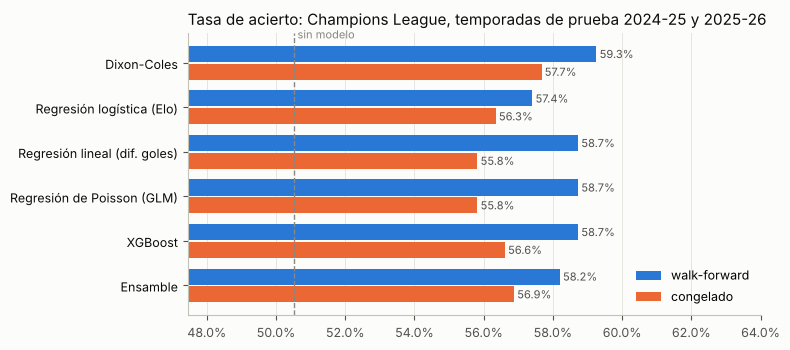

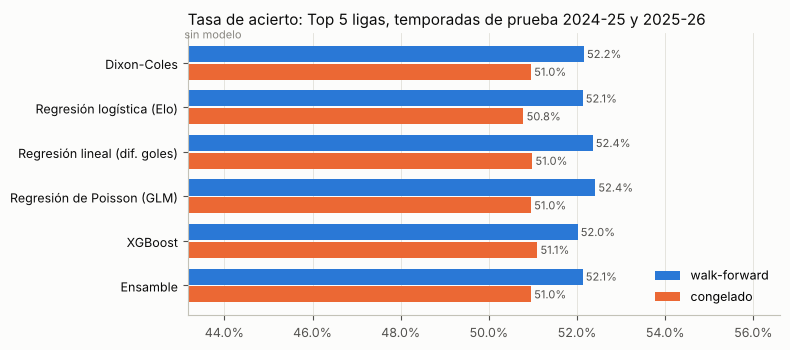

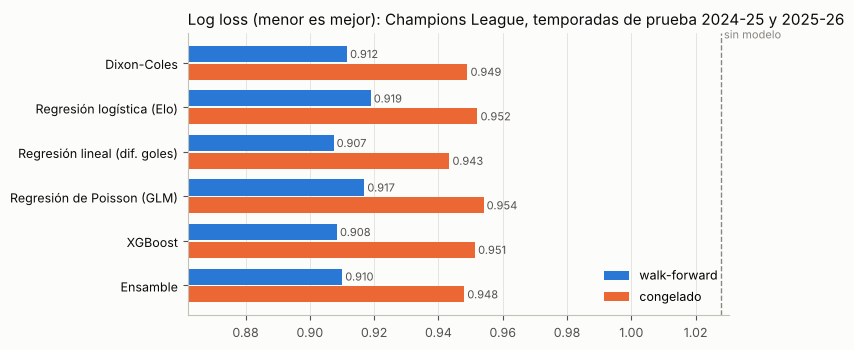

In [19]:
for sub in ["Champions League", "Top 5 ligas"]:
    plot_metricas(rep, "accuracy", sub, fn=f"salidas/acierto_{sub.split()[0].lower()}.png"); plt.show()
plot_metricas(rep, "log_loss", "Champions League", fn="salidas/logloss_champions.png"); plt.show()

### Calibración, confianza y apuestas simuladas

Un modelo calibrado cumple esto: de los partidos donde dice 70%, el favorito gana cerca de 70% de las veces. Abajo se revisa eso y se simula apostar 1 unidad cada vez que el modelo ve valor contra Bet365.

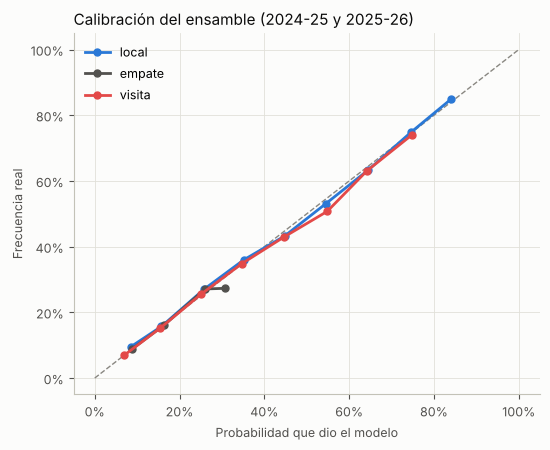

,confianza del favorito,partidos,acierto real,prob. media
0,0%-40%,1064,0.359,0.380
1,40%-50%,2660,0.432,0.448
2,50%-60%,1722,0.524,0.546
3,60%-70%,1013,0.633,0.644
4,70%-80%,933,0.746,0.746
5,80%-100%,244,0.852,0.840


Empates reales: 25.1% | veces que el empate fue la opción más probable: 0.0%


,apuestas,aciertos,beneficio_u,roi,roi_ic90,estrategia
0,3701,1086,-458.34,-0.123842,"(-0.16876898135639018, -0.07995393136990003)",modelo con ventaja > 5%
1,2470,661,-310.71,-0.125794,"(-0.18448603238866396, -0.0686433198380567)",modelo con ventaja > 10%
2,7069,2720,-345.48,-0.048873,"(-0.0768221813552129, -0.020709294101004392)",siempre al favorito


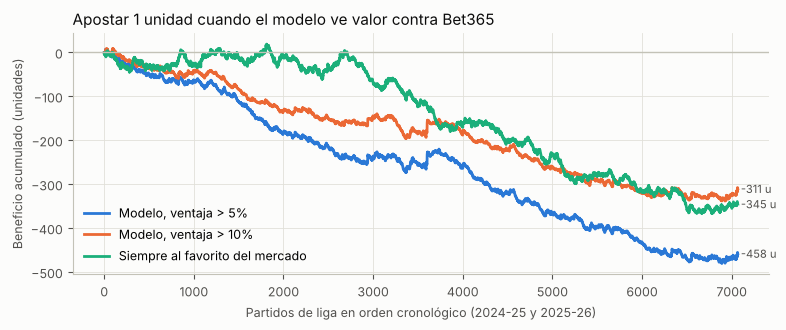

peso del modelo 0%: log loss 0.9673
peso del modelo 10%: log loss 0.9678
peso del modelo 20%: log loss 0.9686
peso del modelo 30%: log loss 0.9696
peso del modelo 50%: log loss 0.9722
peso del modelo 100%: log loss 0.9835


In [20]:
te = bt["idx_test"]; y_te = df.loc[te, "res"].values
P_wf = bt["preds"]["walk-forward"]["ensamble"]
plot_calibracion(P_wf, y_te, fn="salidas/calibracion.png"); plt.show()

conf = P_wf.max(1); filas = []
for lo, hi in [(0, .4), (.4, .5), (.5, .6), (.6, .7), (.7, .8), (.8, 1.01)]:
    m = (conf >= lo) & (conf < hi)
    filas.append({"confianza del favorito": f"{lo:.0%}-{min(hi,1):.0%}", "partidos": int(m.sum()),
                  "acierto real": (P_wf[m].argmax(1) == y_te[m]).mean(), "prob. media": conf[m].mean()})
conf_tab = pd.DataFrame(filas); conf_tab.to_csv("salidas/confianza.csv", index=False)
display(conf_tab.round(3))
print("Empates reales:", f"{(y_te==1).mean():.1%}", "| veces que el empate fue la opción más probable:", f"{(P_wf.argmax(1)==1).mean():.1%}")

odds = df.loc[te, ["oh", "od", "oa"]].values.astype(float)
ok = np.isfinite(odds).all(1) & (df.loc[te, "is_euro"] == 0).values
curvas, resumen = {}, []
for edge in [0.05, 0.10]:
    s, cur = value_bets_sim(P_wf[ok], *odds[ok].T, y_te[ok], edge=edge)
    curvas[f"Modelo, ventaja > {edge:.0%}"] = cur; s["estrategia"] = f"modelo con ventaja > {edge:.0%}"; resumen.append(s)
s, cur = value_bets_sim(market_probs(*odds[ok].T), *odds[ok].T, y_te[ok], edge=-1)
curvas["Siempre al favorito del mercado"] = cur; s["estrategia"] = "siempre al favorito"; resumen.append(s)
roi_tab = pd.DataFrame(resumen); roi_tab.to_csv("salidas/roi.csv", index=False)
display(roi_tab)
plot_roi(curvas, fn="salidas/roi.png"); plt.show()

for w in [0, .1, .2, .3, .5, 1]:
    PP = w * P_wf[ok] + (1 - w) * market_probs(*odds[ok].T)
    print(f"peso del modelo {w:.0%}: log loss {metrics(PP, y_te[ok])['log_loss']:.4f}")

### ¿Sirve para over/under y ambos anotan?

Los mercados de goles se derivan de la matriz de marcadores de Dixon-Coles. Aquí se revisan en las mismas dos temporadas de prueba.

In [21]:
idx = df.index[df.season.isin(TEMPORADAS_PROBAR) & X.dc_lh.notna()]
M = score_matrix(X.loc[idx, "dc_lh"].values, X.loc[idx, "dc_la"].values, X.loc[idx, "rho"].values)
tot = np.add.outer(np.arange(11), np.arange(11))
p_over = M[:, tot > 2.5].sum(1); p_btts = M[:, 1:, 1:].sum((1, 2))
y_over = ((df.loc[idx, "hg"] + df.loc[idx, "ag"]) > 2.5).values; y_btts = ((df.loc[idx, "hg"] > 0) & (df.loc[idx, "ag"] > 0)).values
o = df.loc[idx, ["o25", "u25"]].values.astype(float); okm = np.isfinite(o).all(1) & (df.loc[idx, "is_euro"] == 0).values
p_mk = (1 / o[okm, 0]) / (1 / o[okm, 0] + 1 / o[okm, 1]); ucl = (df.loc[idx, "div"] == "UCL").values
goles_tab = pd.DataFrame([
    {"mercado": "Over 2.5, ligas", "partidos": int(okm.sum()), "acierto modelo": ((p_over[okm] > .5) == y_over[okm]).mean(), "acierto Bet365": ((p_mk > .5) == y_over[okm]).mean()},
    {"mercado": "Over 2.5, Champions", "partidos": int(ucl.sum()), "acierto modelo": ((p_over[ucl] > .5) == y_over[ucl]).mean(), "acierto Bet365": np.nan},
    {"mercado": "Ambos anotan, Champions", "partidos": int(ucl.sum()), "acierto modelo": ((p_btts[ucl] > .5) == y_btts[ucl]).mean(), "acierto Bet365": np.nan}])
goles_tab.to_csv("salidas/goles.csv", index=False)
goles_tab.round(3)

,mercado,partidos,acierto modelo,acierto Bet365
0,"Over 2.5, ligas",6790,0.568,0.577
1,"Over 2.5, Champions",378,0.685,NaN
2,"Ambos anotan, Champions",378,0.582,NaN


## 3. Modelos finales y predicciones de la jornada

Los modelos finales se entrenan con las 5 temporadas más lo jugado en 2026-27. La probabilidad **final** mezcla el ensamble con el mercado:

* El backtest dice que el peso óptimo del modelo frente a Bet365 es casi 0. Las cuotas de esta jornada salen de fuentes sueltas y algunas tienen días de antigüedad, así que aquí el modelo pesa 25% (`PESO_MODELO`). Súbelo a 50% si no tienes cuotas confiables.
* Las bajas se aplican como puntos Elo restados (celda Configuración) y mueven las tasas de gol de Dixon-Coles.

Pesos del ensamble final: {'dc': np.float64(0.23), 'logit': np.float64(0.31), 'lineal': np.float64(0.0), 'poisson': np.float64(0.15), 'xgboost': np.float64(0.3)}


,fecha,hora CET,local,visita,1,X,2,marcador,goles,over 2.5,ambos anotan
0,2026-11-03,18:45,Shakhtar Donetsk,Sp Lisbon,27%,25%,47%,1-1,2.7,50%,53%
1,2026-11-03,18:45,Galatasaray,Stuttgart,43%,24%,33%,1-1,3.4,65%,66%
2,2026-11-03,21:00,Ath Madrid,Bayern Munich,29%,22%,49%,1-1,3.6,69%,68%
3,2026-11-03,21:00,Barcelona,Aston Villa,69%,19%,11%,2-0,3.6,70%,59%
4,2026-11-03,21:00,Feyenoord,Inter,23%,22%,54%,1-2,3.4,65%,63%
5,2026-11-03,21:00,Bodo/Glimt,Lille,50%,24%,26%,1-1,3.0,56%,57%
6,2026-11-03,21:00,LASK,Slovan Bratislava,65%,20%,15%,2-1,3.4,65%,59%
7,2026-11-03,21:00,Man United,Roma,42%,25%,33%,1-1,2.9,54%,57%
8,2026-11-03,21:00,Villarreal,Paris SG,24%,19%,57%,1-2,3.7,70%,67%
9,2026-11-04,18:45,Fenerbahce,Liverpool,20%,21%,59%,1-2,3.7,70%,66%


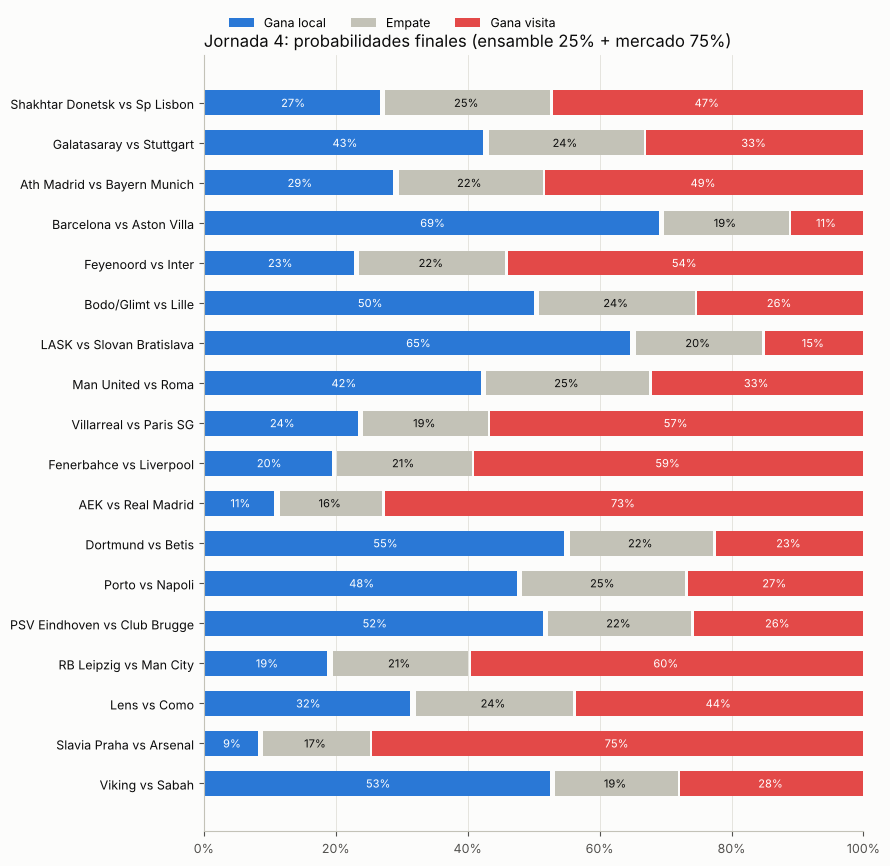

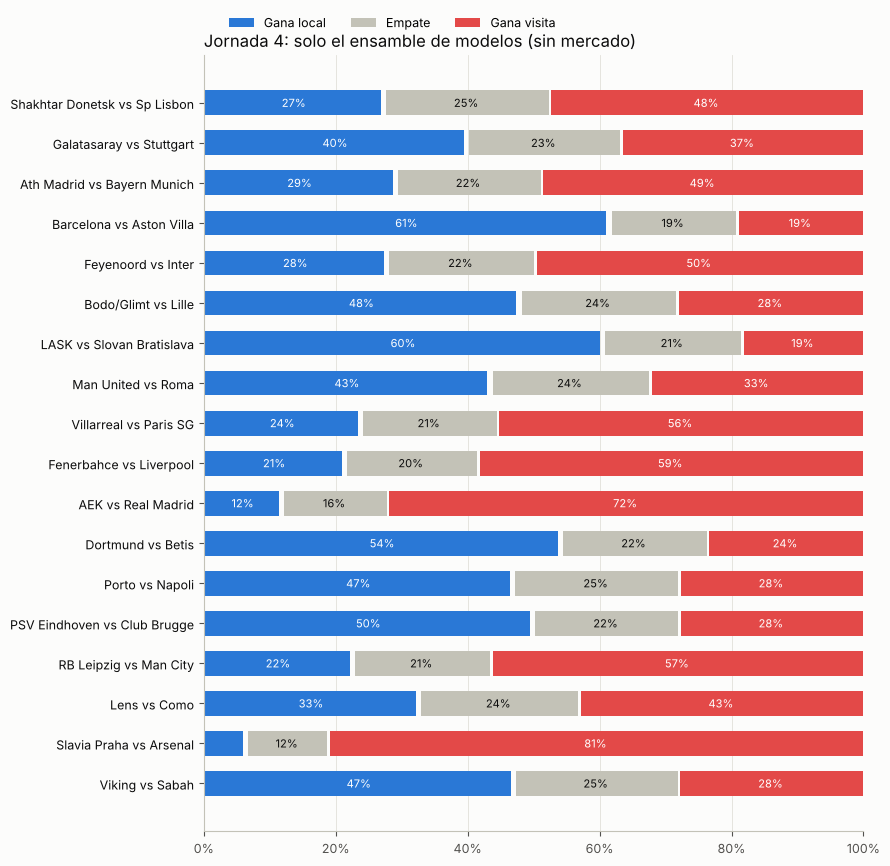

In [22]:
PESO_MODELO = 0.25
prod, w_prod = train_production(df, X, bt)
print("Pesos del ensamble final:", {k: round(v, 2) for k, v in w_prod.items()})
estado = current_state(df, seeds, ref_date=PARTIDOS[0][0])
fx = fixtures_df(PARTIDOS)
pred, sims, X_fx = predict_fixtures(fx, estado, prod, w_prod, PESO_MODELO, ajustes=AJUSTES_BAJAS, n_sims=N_SIMULACIONES)
pred_sin, _, _ = predict_fixtures(fx, estado, prod, w_prod, PESO_MODELO, ajustes={}, n_sims=20_000)
pred["final_1_sin_bajas"], pred["final_2_sin_bajas"] = pred_sin.final_1, pred_sin.final_2
pred["ens_1_sin_bajas"], pred["ens_2_sin_bajas"] = pred_sin.ensamble_1, pred_sin.ensamble_2
pred["fuente_cuotas"] = fx.fuente_cuotas
pred.drop(columns=["top_marcadores"]).to_csv("salidas/predicciones.csv", index=False)
json.dump({f"{r.local} vs {r.visita}": r.top_marcadores for r in pred.itertuples()}, open("salidas/marcadores.json", "w"), indent=1)

resumen = pred[["fecha", "hora_CET", "local", "visita", "final_1", "final_X", "final_2", "marcador_probable", "goles_esp", "over25", "btts"]].copy()
resumen.columns = ["fecha", "hora CET", "local", "visita", "1", "X", "2", "marcador", "goles", "over 2.5", "ambos anotan"]
display(resumen.style.format({"1": "{:.0%}", "X": "{:.0%}", "2": "{:.0%}", "goles": "{:.1f}", "over 2.5": "{:.0%}", "ambos anotan": "{:.0%}"}))
plot_partidos(pred, "Jornada 4: probabilidades finales (ensamble 25% + mercado 75%)", fn="salidas/partidos_final.png"); plt.show()
plot_partidos(pred, "Jornada 4: solo el ensamble de modelos (sin mercado)", col="ensamble", fn="salidas/partidos_modelo.png"); plt.show()

### Cada modelo por separado, mercado y señales de valor

In [23]:
cols = ["local", "visita"] + [f"{k}_{s}" for k in ["dc", "logit", "lineal", "poisson", "xgboost", "ensamble", "mercado"] for s in ["1", "X", "2"]] + ["cuotas"]
display(pred[cols].round(2))
print("Señales de valor (EV contra la cuota real, calculado con el ensamble).")
print("En el backtest este tipo de señal perdió dinero: tómalo como diferencia de opinión, no como apuesta.")
display(pred[["local", "visita", "posible_valor"]])

,local,visita,dc_1,dc_X,dc_2,logit_1,logit_X,logit_2,lineal_1,lineal_X,lineal_2,poisson_1,poisson_X,poisson_2,xgboost_1,xgboost_X,xgboost_2,ensamble_1,ensamble_X,ensamble_2,mercado_1,mercado_X,mercado_2,cuotas
0,Shakhtar Donetsk,Sp Lisbon,0.27,0.27,0.47,0.24,0.23,0.53,0.32,0.24,0.44,0.35,0.32,0.33,0.27,0.23,0.51,0.27,0.25,0.48,0.27,0.26,0.47,completo
1,Galatasaray,Stuttgart,0.39,0.23,0.38,0.42,0.23,0.35,0.41,0.24,0.35,0.39,0.26,0.35,0.38,0.23,0.39,0.40,0.23,0.37,0.44,0.24,0.32,completo
2,Ath Madrid,Bayern Munich,0.33,0.22,0.45,0.26,0.22,0.52,0.27,0.23,0.50,0.26,0.24,0.50,0.31,0.21,0.48,0.29,0.22,0.49,0.29,0.22,0.49,completo
3,Barcelona,Aston Villa,0.59,0.20,0.21,0.61,0.21,0.18,0.58,0.21,0.21,0.56,0.23,0.21,0.66,0.16,0.18,0.61,0.19,0.19,0.72,0.19,0.09,imputado (1 cuota)
4,Feyenoord,Inter,0.24,0.22,0.54,0.27,0.22,0.51,0.32,0.24,0.44,0.31,0.26,0.43,0.30,0.21,0.49,0.28,0.22,0.50,0.22,0.23,0.56,completo
5,Bodo/Glimt,Lille,0.41,0.25,0.33,0.54,0.22,0.24,0.50,0.23,0.27,0.48,0.25,0.27,0.46,0.24,0.30,0.48,0.24,0.28,0.51,0.24,0.25,completo
6,LASK,Slovan Bratislava,0.67,0.19,0.14,0.57,0.22,0.22,0.59,0.21,0.20,0.57,0.23,0.20,0.61,0.22,0.18,0.60,0.21,0.19,0.67,0.19,0.14,completo
7,Man United,Roma,0.41,0.26,0.33,0.44,0.23,0.33,0.43,0.24,0.33,0.41,0.26,0.33,0.45,0.23,0.32,0.43,0.24,0.33,0.42,0.25,0.33,imputado (1 cuota)
8,Villarreal,Paris SG,0.29,0.22,0.49,0.20,0.21,0.59,0.24,0.22,0.54,0.23,0.24,0.53,0.24,0.18,0.58,0.24,0.21,0.56,0.24,0.19,0.57,imputado (1 cuota)
9,Fenerbahce,Liverpool,0.17,0.18,0.64,0.24,0.21,0.55,0.26,0.23,0.51,0.25,0.24,0.51,0.20,0.18,0.62,0.21,0.20,0.59,0.19,0.21,0.60,completo


Señales de valor (EV contra la cuota real, calculado con el ensamble).
En el backtest este tipo de señal perdió dinero: tómalo como diferencia de opinión, no como apuesta.


,local,visita,posible_valor
0,Shakhtar Donetsk,Sp Lisbon,-
1,Galatasaray,Stuttgart,"visita @ 3.00 (EV +11%, Kelly/4 1.3%)"
2,Ath Madrid,Bayern Munich,-
3,Barcelona,Aston Villa,"visita @ 10.50 (EV +103%, Kelly/4 2.7%)"
4,Feyenoord,Inter,"local @ 4.51 (EV +25%, Kelly/4 1.8%)"
5,Bodo/Glimt,Lille,"visita @ 4.00 (EV +13%, Kelly/4 1.1%)"
6,LASK,Slovan Bratislava,"visita @ 6.67 (EV +24%, Kelly/4 1.0%)"
7,Man United,Roma,-
8,Villarreal,Paris SG,-
9,Fenerbahce,Liverpool,"local @ 5.00 (EV +7%, Kelly/4 0.4%)"


In [24]:
for r in pred.itertuples():
    mc = sims[f"{r.local} vs {r.visita}"]
    top = ", ".join(f"{k} ({v:.0%})" for k, v in mc["top_marcadores"].items())
    print(f"{r.local} vs {r.visita}: 1 {mc['p_local']:.0%} | X {mc['p_empate']:.0%} | 2 {mc['p_visita']:.0%} | "
          f"goles {mc['goles_esp']:.1f} (90%: {mc['goles_p5_p95'][0]}-{mc['goles_p5_p95'][1]}) | "
          f"O1.5 {mc['over15']:.0%} O2.5 {mc['over25']:.0%} O3.5 {mc['over35']:.0%} | BTTS {mc['btts']:.0%}\n   marcadores: {top}")

Shakhtar Donetsk vs Sp Lisbon: 1 27% | X 26% | 2 47% | goles 2.7 (90%: 0-6) | O1.5 75% O2.5 50% O3.5 28% | BTTS 53%
   marcadores: 1-1 (12%), 0-1 (10%), 1-2 (9%), 0-2 (8%), 0-0 (8%)
Galatasaray vs Stuttgart: 1 43% | X 23% | 2 34% | goles 3.4 (90%: 1-7) | O1.5 85% O2.5 65% O3.5 44% | BTTS 66%
   marcadores: 1-1 (10%), 2-1 (8%), 1-2 (7%), 2-2 (7%), 1-0 (6%)
Ath Madrid vs Bayern Munich: 1 29% | X 22% | 2 49% | goles 3.6 (90%: 1-7) | O1.5 87% O2.5 69% O3.5 48% | BTTS 68%
   marcadores: 1-1 (9%), 1-2 (9%), 2-2 (7%), 2-1 (7%), 1-3 (6%)
Barcelona vs Aston Villa: 1 70% | X 17% | 2 13% | goles 3.6 (90%: 1-7) | O1.5 88% O2.5 70% O3.5 49% | BTTS 59%
   marcadores: 2-0 (9%), 2-1 (9%), 3-1 (8%), 3-0 (8%), 1-1 (7%)
Feyenoord vs Inter: 1 24% | X 22% | 2 54% | goles 3.4 (90%: 1-7) | O1.5 85% O2.5 65% O3.5 43% | BTTS 63%
   marcadores: 1-2 (10%), 1-1 (10%), 0-2 (7%), 0-1 (7%), 1-3 (7%)
Bodo/Glimt vs Lille: 1 50% | X 24% | 2 26% | goles 3.0 (90%: 0-6) | O1.5 79% O2.5 56% O3.5 34% | BTTS 57%
   marcadore

## 4. Tendencias de la Champions 2026-27 (jornadas 1 a 3)

In [25]:
cur = df[(df["div"] == "UCL") & (df.season == 2026)]
tabla_ucl = standings(cur); tabla_ucl.to_csv("salidas/tabla_ucl.csv")
print(f"Partidos: {len(cur)} | goles por partido: {(cur.hg + cur.ag).mean():.2f} | over 2.5: {((cur.hg + cur.ag) > 2.5).mean():.0%} | "
      f"ambos anotan: {((cur.hg > 0) & (cur.ag > 0)).mean():.0%} | gana local: {(cur.res == 0).mean():.0%} | empate: {(cur.res == 1).mean():.0%}")
hist = df[(df["div"] == "UCL") & df.season.isin([2024, 2025])]
print(f"Referencia 2024-25 y 2025-26: goles {(hist.hg + hist.ag).mean():.2f} | over 2.5 {((hist.hg + hist.ag) > 2.5).mean():.0%} | "
      f"gana local {(hist.res == 0).mean():.0%} | empate {(hist.res == 1).mean():.0%}")
tabla_ucl

Partidos: 54 | goles por partido: 4.09 | over 2.5: 74% | ambos anotan: 67% | gana local: 59% | empate: 11%
Referencia 2024-25 y 2025-26: goles 3.36 | over 2.5 65% | gana local 51% | empate 16%


,PJ,G,E,P,GF,GC,Pts,DG,over25_%,btts_%
equipo,,,,,,,,,,
Paris SG,3,3,0,0,14,5,9,9,100.0,100.0
Aston Villa,3,3,0,0,12,3,9,9,100.0,67.0
Liverpool,3,3,0,0,12,7,9,5,100.0,100.0
Real Madrid,3,3,0,0,10,5,9,5,100.0,100.0
Betis,3,3,0,0,7,4,9,3,67.0,67.0
Stuttgart,3,2,1,0,7,2,7,5,67.0,67.0
Arsenal,3,2,1,0,6,2,7,4,67.0,33.0
Barcelona,3,2,0,1,11,6,6,5,100.0,100.0
Como,3,2,0,1,10,5,6,5,100.0,100.0


## 5. Modo fin de semana (ligas)

El mismo modelo sirve para cualquier partido de las 15 ligas cargadas. En Colab baja el calendario y las cuotas de football-data.co.uk. Para usarlo:

1. Cambia `dias` y `desde` en la celda de abajo.
2. Ejecuta la celda. Si no hay cuotas, la probabilidad final es solo la del modelo.

Para otra jornada de Champions edita `PARTIDOS`, `AJUSTES_BAJAS` y agrega los resultados nuevos a `UCL_2026_27`.

In [26]:
fin_semana = proximos_partidos_ligas(dias=5, desde=pd.Timestamp(PARTIDOS[-1][0]) + pd.Timedelta(days=1))
if len(fin_semana):
    pred_fs, _, _ = predict_fixtures(fin_semana, estado, prod, w_prod, PESO_MODELO, ajustes={}, n_sims=20_000)
    pred_fs["liga"] = fin_semana.competicion.values
    display(pred_fs[["fecha", "liga", "local", "visita", "final_1", "final_X", "final_2", "marcador_probable", "over25"]].round(2))
else:
    print("No hay partidos en la ventana elegida.")

fixtures.csv no disponible: <urlopen error Tunnel connection failed: 403 Forbidden> -> calendario openfootball (sin cuotas)


,fecha,liga,local,visita,final_1,final_X,final_2,marcador_probable,over25
0,2026-11-07,E0,Arsenal,Hull,0.83,0.13,0.04,2-0,0.53
1,2026-11-07,E0,Nott'm Forest,Man City,0.25,0.25,0.51,1-1,0.54
2,2026-11-07,E0,Leeds,Tottenham,0.50,0.26,0.24,1-1,0.53
3,2026-11-07,E0,Fulham,Newcastle,0.35,0.27,0.38,1-1,0.54
4,2026-11-07,E0,Everton,Coventry,0.63,0.23,0.14,1-0,0.43
...,...,...,...,...,...,...,...,...,...
61,2026-11-08,N1,Heerenveen,Feyenoord,0.23,0.23,0.54,1-1,0.63
62,2026-11-08,N1,Twente,Ajax,0.42,0.28,0.31,1-1,0.53
63,2026-11-08,N1,AZ Alkmaar,Groningen,0.56,0.25,0.19,1-1,0.53
64,2026-11-08,N1,Cambuur,PSV Eindhoven,0.07,0.13,0.80,1-3,0.88


## 6. Límites del modelo (léelos antes de apostar)

* **No le gana al mercado.** En 7,069 partidos de liga de prueba, el log loss del mercado fue 0.967 y el del ensamble 0.984. Apostar a sus "valores" perdió entre 11% y 16% del dinero apostado.
* **El empate casi nunca es la opción más probable**, aunque ocurre en 1 de cada 4 partidos. Ningún modelo de este tipo lo predice bien.
* **Datos con huecos fuera de Colab.** El espejo de GitHub llega al 20 de septiembre de 2026 en ligas. Sin football-data.co.uk el modelo no ve la forma doméstica de octubre.
* **Equipos con poca historia** (Sabah, Slavia, Slovan, Kairat): su fuerza sale de un Elo por país más 3 a 10 partidos europeos. Ahí el error es mayor.
* **Las bajas son un ajuste manual**, con fuentes secundarias. Si un titular sí juega, el ajuste sobra.
* **Las cuotas cargadas son fotos de distintas casas y fechas.** Algunas se completaron con el modelo (columna `cuotas`). Revisa la cuota real antes de decidir.